In [1]:
import pandas as pd
df = pd.read_csv('Datasets/train_test_network.csv', encoding='utf-8')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 211043 entries, 0 to 211042
Data columns (total 44 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   src_ip                  211043 non-null  object 
 1   src_port                211043 non-null  int64  
 2   dst_ip                  211043 non-null  object 
 3   dst_port                211043 non-null  int64  
 4   proto                   211043 non-null  object 
 5   service                 211043 non-null  object 
 6   duration                211043 non-null  float64
 7   src_bytes               211043 non-null  int64  
 8   dst_bytes               211043 non-null  int64  
 9   conn_state              211043 non-null  object 
 10  missed_bytes            211043 non-null  int64  
 11  src_pkts                211043 non-null  int64  
 12  src_ip_bytes            211043 non-null  int64  
 13  dst_pkts                211043 non-null  int64  
 14  dst_ip_bytes        

In [2]:
# df.head()
# for col in df.select_dtypes(include='object').columns:
#     print(f"{col}: {df[col].nunique()} unique values")
df.dtypes

src_ip                     object
src_port                    int64
dst_ip                     object
dst_port                    int64
proto                      object
service                    object
duration                  float64
src_bytes                   int64
dst_bytes                   int64
conn_state                 object
missed_bytes                int64
src_pkts                    int64
src_ip_bytes                int64
dst_pkts                    int64
dst_ip_bytes                int64
dns_query                  object
dns_qclass                  int64
dns_qtype                   int64
dns_rcode                   int64
dns_AA                     object
dns_RD                     object
dns_RA                     object
dns_rejected               object
ssl_version                object
ssl_cipher                 object
ssl_resumed                object
ssl_established            object
ssl_subject                object
ssl_issuer                 object
http_trans_dep

In [3]:
import pandas as pd
import numpy as np
import pennylane as qml
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_curve, auc
from sklearn.utils.class_weight import compute_class_weight
from imblearn.over_sampling import SMOTE
from scipy.stats import mode
import time
import os
from joblib import dump, load
import os
from scipy.stats import mode
from tqdm import tqdm
from sklearn.decomposition import PCA
import torch
import torch.nn as nn
import torch.optim as optim
    

SEED = 42
NUM_FEATURES = 13

In [4]:
categorical_cols = df.select_dtypes(include='object').columns
label_encoders = {}

le = LabelEncoder()
for col in categorical_cols:
    df[col] = le.fit_transform(df[col].astype(str))
    label_encoders[col] = le
    print(f"\nColumn: {col}")
    print(dict(zip(le.classes_, le.transform(le.classes_))))

feature_names = df.columns

X = df.drop('label', axis=1)
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print(f"Original class distribution: {np.bincount(y_train)}")

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


pca = PCA(n_components=NUM_FEATURES, random_state=SEED)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test_scaled)

print("Features Selected: ")
for i, component in enumerate(pca.components_):
    # Get the index of the feature with the largest absolute value in this component
    important_idx = np.argmax(np.abs(component))
    print(f"Principal Component {i+1}: most important feature is '{feature_names[important_idx]}'")


X_train = X_train_pca
X_test = X_test_pca

print(X_train.shape)
print(X_test.shape)



Column: src_ip
{'13.55.50.68': 0, '172.17.0.5': 1, '172.17.0.7': 2, '172.17.0.8': 3, '192.168.1.1': 4, '192.168.1.103': 5, '192.168.1.133': 6, '192.168.1.152': 7, '192.168.1.169': 8, '192.168.1.17': 9, '192.168.1.180': 10, '192.168.1.184': 11, '192.168.1.186': 12, '192.168.1.190': 13, '192.168.1.191': 14, '192.168.1.192': 15, '192.168.1.193': 16, '192.168.1.194': 17, '192.168.1.195': 18, '192.168.1.250': 19, '192.168.1.30': 20, '192.168.1.31': 21, '192.168.1.32': 22, '192.168.1.33': 23, '192.168.1.34': 24, '192.168.1.36': 25, '192.168.1.37': 26, '192.168.1.38': 27, '192.168.1.39': 28, '192.168.1.46': 29, '192.168.1.49': 30, '192.168.1.6': 31, '192.168.1.79': 32, '199.115.158.193': 33, '203.14.129.10': 34, '220.158.215.20': 35, '2405:6e00:10ce:2c00:20c:29ff:fed2:b002': 36, '2405:6e00:10ce:2c00:20c:29ff:feee:e07a': 37, '2405:6e00:10ce:2c00:8520:4eba:6770:702a': 38, '2405:6e00:10ce:2c00:9064:17:85d2:57d4': 39, '2405:6e00:10ce:2c00:c058:dbaa:f212:a2d8': 40, 'fe80::1087:c341:7263:ead3': 41

In [5]:
from joblib import dump, load

# dump(scaler, 'scaler.joblib')
# dump(pca, 'pca.joblib')
dump(label_encoders, 'label_encoders.joblib')
# dump(categorical_cols, 'categorical_cols.joblib')
# dump(feature_names, 'feature_names.joblib')

['label_encoders.joblib']

In [5]:
def create_sequential_batches(X_train, y_train, X_test, y_test, train_batch_size=300, test_batch_size=100):
    train_batches = []
    test_batches = []
    num_batches = min(len(X_train) // train_batch_size, len(X_test) // test_batch_size)
    for i in range(num_batches):
        train_start = i * train_batch_size
        train_end = train_start + train_batch_size
        test_start = i * test_batch_size
        test_end = test_start + test_batch_size
        train_batches.append((X_train[train_start:train_end], y_train[train_start:train_end]))
        test_batches.append((X_test[test_start:test_end], y_test[test_start:test_end]))
    return train_batches, test_batches

# Usage:
train_batches, test_batches = create_sequential_batches(X_train, y_train, X_test, y_test)

In [6]:
SEED = 42
TRAIN_BATCH_SIZE = 300
TEST_BATCH_SIZE = 100
NUM_BATCHES = 10

from joblib import Parallel, delayed


dev = qml.device("default.qubit", wires=NUM_FEATURES)

@qml.qnode(dev)
def kernel_circuit(x1, x2):
    qml.AngleEmbedding(x1, wires=range(NUM_FEATURES))
    qml.adjoint(qml.AngleEmbedding)(x2, wires=range(NUM_FEATURES))
    return qml.probs(wires=range(NUM_FEATURES))

def kernel(x1, x2):
    return kernel_circuit(x1, x2)

def compute_kernel_matrix(X1, X2):
    n_samples_1, n_samples_2 = len(X1), len(X2)
    kernel_matrix = np.zeros((n_samples_1, n_samples_2))
    for i in range(n_samples_1):
        for j in range(n_samples_2):
            probs = kernel_circuit(X1[i], X2[j])
            kernel_matrix[i, j] = probs[0]  # this represents the inner product now
    return kernel_matrix

In [7]:
from sklearn.model_selection import GridSearchCV

# Store metrics
all_test_preds = []
all_test_labels = []
train_accuracies = []
test_accuracies = []


for batch_idx in range(10):
    print(f"\nBatch {batch_idx + 1}/10")

    # Get batch data
    X_batch_train, y_batch_train = train_batches[batch_idx]
    X_batch_test, y_batch_test = test_batches[batch_idx]

    print("- Computing training kernel...")
    K_train = compute_kernel_matrix(X_batch_train, X_batch_train)

    print("- Computing testing kernel...")
    K_test = compute_kernel_matrix(X_batch_test, X_batch_train)

    if batch_idx == 4:
        K_train_4 = K_train
        K_test_4 = K_test

    # Hyperparameter tuning for C
    print("- Tuning C value...")
    param_grid = {"C": [0.1, 1, 10, 20, 30, 40, 50, 60]}
    grid = GridSearchCV(SVC(kernel='precomputed'), param_grid, cv=3)
    grid.fit(K_train, y_batch_train)
    best_model = grid.best_estimator_
    print(f"- Best C: {grid.best_params_['C']}")


    # Predictions
    y_pred = best_model.predict(K_test)
    all_test_preds.append(y_pred)
    all_test_labels.append(y_batch_test)

    # Overfitting check
    train_preds = best_model.predict(K_train)
    train_acc = accuracy_score(y_batch_train, train_preds)
    test_acc = accuracy_score(y_batch_test, y_pred)
    train_accuracies.append(train_acc)
    test_accuracies.append(test_acc)

    print(f"- Train Accuracy: {train_acc:.4f}")
    print(f"- Test Accuracy: {test_acc:.4f}")
    if train_acc - test_acc > 0.10:
        print("- Possible overfitting detected (Train >> Test)")



Batch 1/10
- Computing training kernel...
- Computing testing kernel...
- Tuning C value...
- Best C: 10
- Train Accuracy: 0.9967
- Test Accuracy: 0.9800

Batch 2/10
- Computing training kernel...
- Computing testing kernel...
- Tuning C value...
- Best C: 1
- Train Accuracy: 0.9900
- Test Accuracy: 0.9500

Batch 3/10
- Computing training kernel...
- Computing testing kernel...
- Tuning C value...
- Best C: 10
- Train Accuracy: 1.0000
- Test Accuracy: 0.9900

Batch 4/10
- Computing training kernel...
- Computing testing kernel...
- Tuning C value...
- Best C: 1
- Train Accuracy: 0.9933
- Test Accuracy: 0.9900

Batch 5/10
- Computing training kernel...
- Computing testing kernel...
- Tuning C value...
- Best C: 10
- Train Accuracy: 1.0000
- Test Accuracy: 0.9900

Batch 6/10
- Computing training kernel...
- Computing testing kernel...
- Tuning C value...
- Best C: 1
- Train Accuracy: 0.9933
- Test Accuracy: 0.9800

Batch 7/10
- Computing training kernel...
- Computing testing kernel...


Text(0.5, 1.0, 'Quantum Kernel (4th) Train Matrix')

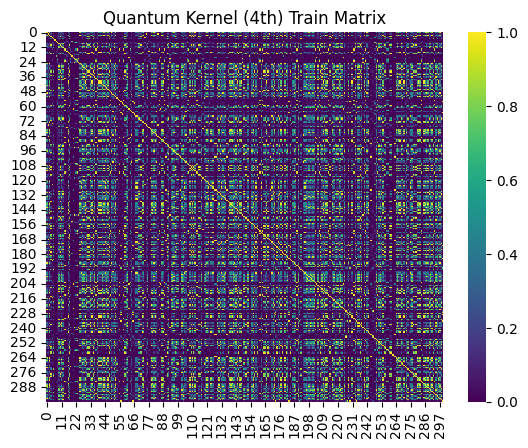

In [8]:
sns.heatmap(K_train_4, cmap="viridis")
plt.title("Quantum Kernel (4th) Train Matrix")

Text(0.5, 1.0, 'Quantum Kernel (10th) Train Matrix')

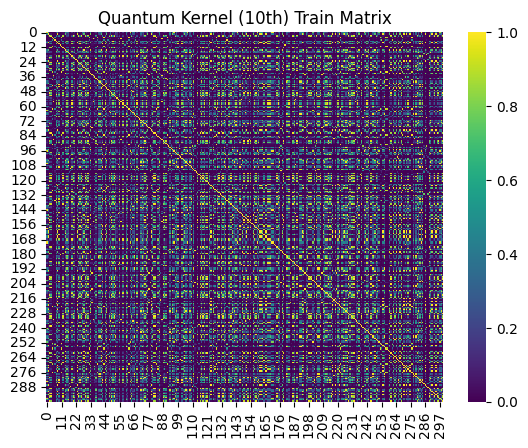

In [9]:
sns.heatmap(K_train, cmap="viridis")
plt.title("Quantum Kernel (10th) Train Matrix")

Text(0.5, 1.0, 'Quantum Kernel Test Matrix')

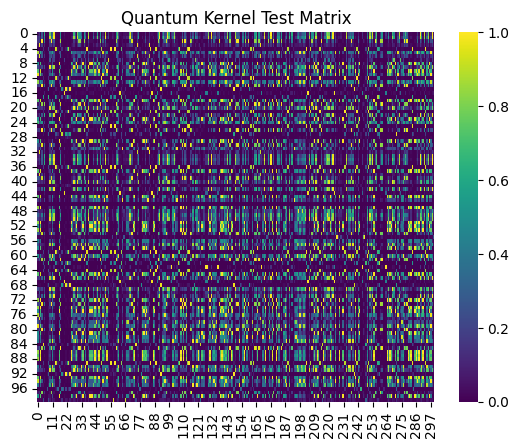

In [10]:
sns.heatmap(K_test_4, cmap="viridis")
plt.title("Quantum Kernel Test Matrix")

Text(0.5, 1.0, 'Quantum Kernel (10th) Test Matrix')

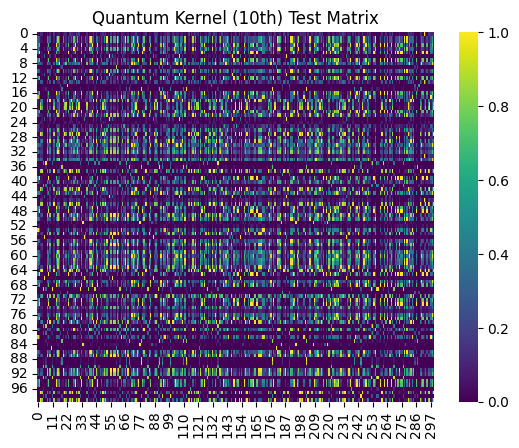

In [11]:
sns.heatmap(K_test, cmap="viridis")
plt.title("Quantum Kernel (10th) Test Matrix")


Final Batched QSVM Accuracy: 0.9720
Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.91      0.94       252
           1       0.97      0.99      0.98       748

    accuracy                           0.97      1000
   macro avg       0.97      0.95      0.96      1000
weighted avg       0.97      0.97      0.97      1000



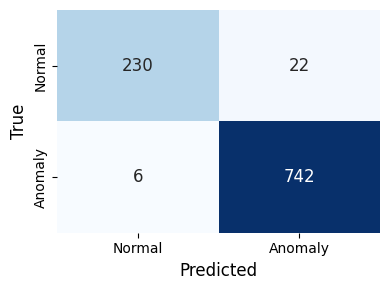

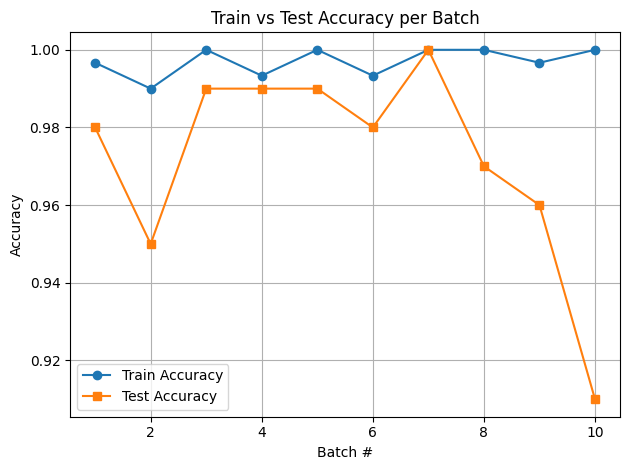

In [12]:
# Final evaluation
all_test_preds = np.concatenate(all_test_preds)
all_test_labels = np.concatenate(all_test_labels)

final_acc = accuracy_score(all_test_labels, all_test_preds)
print(f"\nFinal Batched QSVM Accuracy: {final_acc:.4f}")
print("Classification Report:\n", classification_report(all_test_labels, all_test_preds))

# Confusion matrix
cm = confusion_matrix(all_test_labels, all_test_preds)
plt.figure(figsize=(4, 3))
sns.heatmap(cm, annot=True, fmt='d', cmap="Blues", xticklabels=["Normal", "Anomaly"], yticklabels=["Normal", "Anomaly"], cbar=False, annot_kws={"size": 12})
# plt.title("Confusion Matrix - Ensemble QSVM")
plt.xlabel("Predicted", fontsize=12)
plt.ylabel("True", fontsize=12)
plt.tight_layout()
plt.show()

# Plot train vs test accuracy
plt.plot(range(1, 11), train_accuracies, label="Train Accuracy", marker='o')
plt.plot(range(1, 11), test_accuracies, label="Test Accuracy", marker='s')
plt.title("Train vs Test Accuracy per Batch")
plt.xlabel("Batch #")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [13]:
from sklearn.metrics import f1_score

f1 = f1_score(all_test_labels, all_test_preds)

print(f"F1 Score QSVM: {f1:.4f}")

F1 Score QSVM: 0.9815


In [14]:
from sklearn.metrics import average_precision_score, precision_recall_curve, auc

auprc_qsvm = average_precision_score(all_test_labels, all_test_preds)

print(f"AUPRC QSVM: {auprc_qsvm:.4f}")

AUPRC QSVM: 0.9694


In [16]:
# #def tpr_at_fpr(y_true, y_scores, target_fpr):
# #    """Calculate TPR at a specific FPR threshold"""
# #    fpr, tpr, thresholds = roc_curve(y_true, y_scores)
# #    
# #    # Find the index where FPR is closest to target_fpr
# #    idx = np.argmin(np.abs(fpr - target_fpr))
# #    
# #    return tpr[idx], fpr[idx], thresholds[idx]


# #tpr_001, actual_fpr_001, thresh_001 = tpr_at_fpr(all_test_labels, all_test_preds, 0.001)  # 0.1%
# #tpr_01, actual_fpr_01, thresh_01 = tpr_at_fpr(all_test_labels, all_test_preds, 0.01)      # 1%

# #print("TPR@FPR (0.1% and 1%)")
# #print(f"TPR at 0.1% FPR: {tpr_001:.4f} (actual FPR: {actual_fpr_001:.4f}, threshold: {thresh_001:.4f})")
# #print(f"TPR at 1% FPR: {tpr_01:.4f} (actual FPR: {actual_fpr_01:.4f}, threshold: {thresh_01:.4f})")


# # def tpr_at_fpr_interp(fpr, tpr, target_fpr):
# #     return np.interp(target_fpr, fpr, tpr)

# # def compute_tpr_at_fpr(y_true, y_score, fpr_targets=[0.001, 0.01]):
# #     fpr, tpr, _ = roc_curve(y_true, y_score)
# #     print("Min FPR:", fpr.min())
# #     print("Max FPR:", fpr.max())

# #     results = {}
# #     for target in fpr_targets:
# #         idx = np.where(fpr <= target)[0]
# #         results[f"TPR@{target*100:.1f}%FPR"] = tpr[idx[-1]] if len(idx) > 0 else 0.0
    
# #     tpr_0_1 = tpr_at_fpr_interp(fpr, tpr, 0.001)  # 0.1%
# #     tpr_1   = tpr_at_fpr_interp(fpr, tpr, 0.01)   # 1%

# #     print("Interpolated TPR@0.1% FPR:", tpr_0_1)
# #     print("Interpolated TPR@1% FPR:", tpr_1)

# #     import matplotlib.pyplot as plt
# #     plt.plot(fpr, tpr, label="ROC")
# #     plt.xlim(0, 0.02)   # zoom in to 0–2% FPR
# #     plt.ylim(0, 1)
# #     plt.xlabel("False Positive Rate")
# #     plt.ylabel("True Positive Rate")
# #     plt.legend()
# #     plt.show()

    
# #     return results

# from sklearn.metrics import roc_curve
# def compute_tpr_at_fpr(y_true, y_score, fpr_targets=[0.001, 0.01]):
#     fpr, tpr, _ = roc_curve(y_true, y_score)
#     print("Min FPR:", fpr.min())
#     print("Max FPR:", fpr.max())

#     results = {}
#     for target in fpr_targets:
#         # Always interpolate for robustness
#         results[f"TPR@{target*100:.1f}%FPR"] = float(np.interp(target, fpr, tpr))

#     # Plot zoomed-in ROC curve
#     import matplotlib.pyplot as plt
#     plt.plot(fpr, tpr, label="ROC")
#     plt.xlim(0, 0.02)   # zoom in to 0–2% FPR
#     plt.ylim(0, 1)
#     plt.xlabel("False Positive Rate")
#     plt.ylabel("True Positive Rate")
#     plt.legend()
#     plt.show()

#     return results


# # Example
# metrics = compute_tpr_at_fpr(all_test_labels, all_test_preds)
# print(metrics)


In [15]:
import numpy as np

def compute_kta(kernel_matrix, labels):
    """
    Compute Kernel Target Alignment (KTA).
    :param kernel_matrix: (n x n) kernel matrix (usually training)
    :param labels: (n,) label vector
    :return: alignment score (float)
    """
    # Convert labels to +1 / -1
    y = np.where(labels == 1, 1, -1)
    target_matrix = np.outer(y, y)

    # Frobenius inner product
    numerator = np.sum(kernel_matrix * target_matrix)
    denominator = np.linalg.norm(kernel_matrix, 'fro') * np.linalg.norm(target_matrix, 'fro')

    return numerator / denominator


In [16]:
n_layers = 7


def qnn_circuit(inputs, weights):
    qml.AngleEmbedding(inputs, wires=range(NUM_FEATURES))
    qml.StronglyEntanglingLayers(weights, wires=range(NUM_FEATURES))
    return [qml.expval(qml.PauliZ(i)) for i in range(NUM_FEATURES)]

qnode = qml.QNode(qnn_circuit, dev, interface="torch")

class QNNClassifier(nn.Module):
    def __init__(self, n_layers, n_qubits):
        super().__init__()
        weight_shapes = {"weights": (n_layers, n_qubits, 3)}
        self.qlayer = qml.qnn.TorchLayer(qnode, weight_shapes)
        self.fc = nn.Linear(n_qubits, 1)
    
    def forward(self, x):
        x = self.qlayer(x)
        x = self.fc(x)
        return x  # No sigmoid here

<generator object Module.parameters at 0x7f01745843c0>
Epoch 10/100, Loss: 0.0702
Epoch 20/100, Loss: 0.0454
Epoch 30/100, Loss: 0.0363
Epoch 40/100, Loss: 0.0299
Epoch 50/100, Loss: 0.0302
Epoch 60/100, Loss: 0.0232
Epoch 70/100, Loss: 0.0237
Epoch 80/100, Loss: 0.0236
Epoch 90/100, Loss: 0.0188
Epoch 100/100, Loss: 0.0233
QNN Accuracy on Test Data: 0.9940
Classification Report:
               precision    recall  f1-score   support

           0       0.99      0.98      0.99       252
           1       0.99      1.00      1.00       748

    accuracy                           0.99      1000
   macro avg       0.99      0.99      0.99      1000
weighted avg       0.99      0.99      0.99      1000



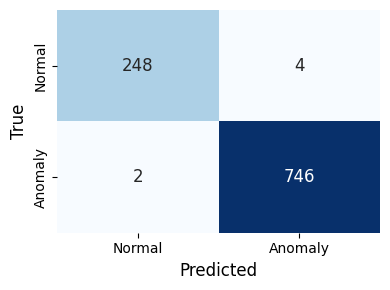

In [17]:
X_train_300 = X_train[:3000]
X_test_100 = X_test[:1000]
y_train_300 = y_train[:3000]
y_test_100 = y_test[:1000]

loss_values = []

# Prepare data
X_train_tensor = torch.tensor(X_train_300, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train_300.values, dtype=torch.float32).unsqueeze(1)
X_test_tensor = torch.tensor(X_test_100, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test_100.values, dtype=torch.float32).unsqueeze(1)

# Use DataLoader for mini-batch training
from torch.utils.data import TensorDataset, DataLoader
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

# Model, loss, optimizer
model = QNNClassifier(n_layers=n_layers, n_qubits=NUM_FEATURES)
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)
print(model.parameters())

# Training loop
epochs = 100
for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    epoch_loss = running_loss / len(train_loader)
    loss_values.append(epoch_loss)
    if (epoch+1) % 10 == 0:
        print(f"Epoch {epoch+1}/{epochs}, Loss: {running_loss/len(train_loader):.4f}")

# Evaluation
model.eval()
# with torch.no_grad():
#     y_pred_logits = model(X_test_tensor)
#     qnn_preds = (torch.sigmoid(y_pred_logits) > 0.5).int().squeeze().numpy()

with torch.no_grad():
    y_pred_logits = model(X_test_tensor)  # shape: (N, 1)
    qnn_sigmoid = torch.sigmoid(y_pred_logits).squeeze()  # shape: (N,)
    qnn_preds = (qnn_sigmoid > 0.5).int().numpy()

    # Convert to probability distribution over 2 classes: [P(class 0), P(class 1)]
    qnn_probs = torch.stack([1 - qnn_sigmoid, qnn_sigmoid], dim=1).cpu().numpy()  # shape: (N, 2)


accuracy_qnn = accuracy_score(y_test_100, qnn_preds)
print(f"QNN Accuracy on Test Data: {accuracy_qnn:.4f}")

print("Classification Report:\n", classification_report(y_test_100, qnn_preds))

cm = confusion_matrix(y_test_100, qnn_preds)
plt.figure(figsize=(4, 3))
sns.heatmap(cm, annot=True, fmt='d', cmap="Blues", xticklabels=["Normal", "Anomaly"], yticklabels=["Normal", "Anomaly"], cbar=False, annot_kws={"size": 12})
# plt.title("Confusion Matrix - QNN")
plt.xlabel("Predicted", fontsize=12)
plt.ylabel("True", fontsize=12)
plt.tight_layout()
plt.show()

In [18]:
f2 = f1_score(y_test_tensor, qnn_preds)

print(f"F1 score QNN: {f2:.4f}")

F1 score QNN: 0.9960


In [19]:
auprc_qsvm = average_precision_score(y_test_tensor, qnn_preds)

print(f"AUPRC QNN: {auprc_qsvm:.4f}")

AUPRC QNN: 0.9940


In [22]:
metrics = compute_tpr_at_fpr(y_test_tensor, qnn_preds)
print(metrics)

NameError: name 'compute_tpr_at_fpr' is not defined

In [ ]:
from joblib import dump, load

dump(model, 'final_model(13  qnn).joblib')



['final_model(13  qnn).joblib']

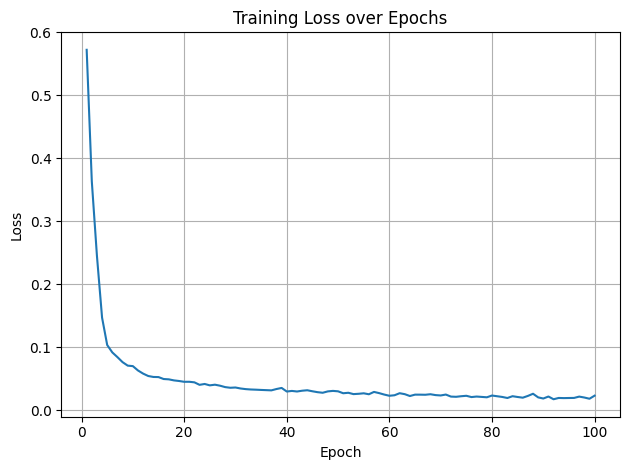

In [20]:
plt.plot(range(1, epochs + 1), loss_values, label="Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss over Epochs")
plt.grid(True)
plt.tight_layout()
plt.show()

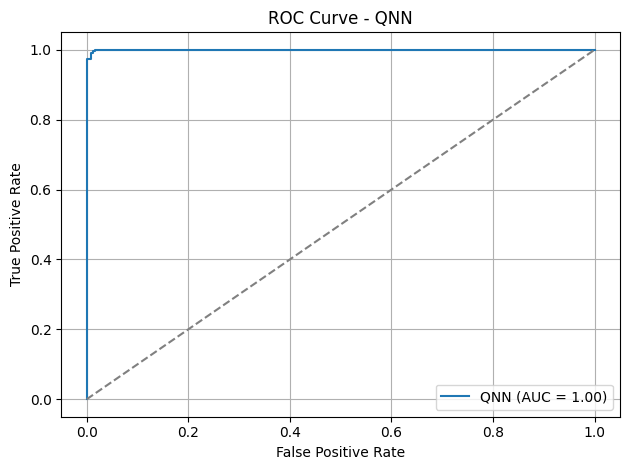

In [21]:
from sklearn.metrics import roc_curve, auc

fpr, tpr, _ = roc_curve(y_test_100, qnn_sigmoid.numpy())
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, label=f'QNN (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - QNN")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
qnn_model = model

/tmp/ipykernel_8987/2432326595.py:9: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


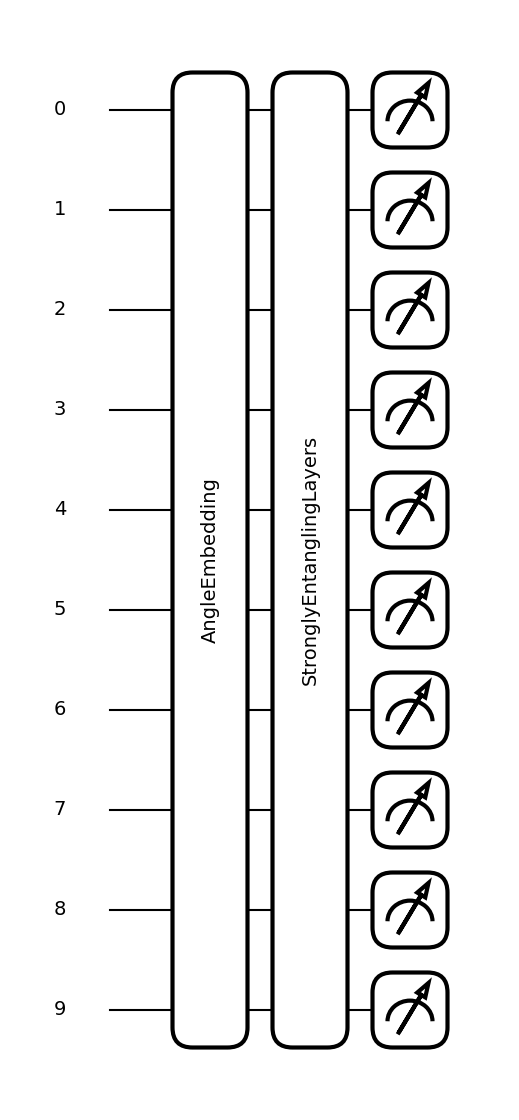

Circuit Diagram (Text):
0: ─╭AngleEmbedding(M0)─╭StronglyEntanglingLayers(M1)─┤  <Z>
1: ─├AngleEmbedding(M0)─├StronglyEntanglingLayers(M1)─┤  <Z>
2: ─├AngleEmbedding(M0)─├StronglyEntanglingLayers(M1)─┤  <Z>
3: ─├AngleEmbedding(M0)─├StronglyEntanglingLayers(M1)─┤  <Z>
4: ─├AngleEmbedding(M0)─├StronglyEntanglingLayers(M1)─┤  <Z>
5: ─├AngleEmbedding(M0)─├StronglyEntanglingLayers(M1)─┤  <Z>
6: ─├AngleEmbedding(M0)─├StronglyEntanglingLayers(M1)─┤  <Z>
7: ─├AngleEmbedding(M0)─├StronglyEntanglingLayers(M1)─┤  <Z>
8: ─├AngleEmbedding(M0)─├StronglyEntanglingLayers(M1)─┤  <Z>
9: ─╰AngleEmbedding(M0)─╰StronglyEntanglingLayers(M1)─┤  <Z>
M0 = 
[ 4.6769414   2.4686687  -0.07749146  0.06696891 -0.17242663  0.03245308
 -0.24383026  0.00868572  0.05848703 -0.29716986]
M1 = 
[[[ 4.788923    5.493941    3.886625  ]
  [ 4.649026    3.05274     2.765472  ]
  [ 1.7290055   0.5966702   2.73053   ]
  [ 4.3801637   1.8724501   3.4222891 ]
  [ 1.235546    5.938858    1.4573761 ]
  [ 5.664032    0.42971933  2.4

TypeError: draw() got an unexpected keyword argument 'expansion_strategy'

In [ ]:
# import matplotlib.pyplot as plt

# # Create a sample input and weights for visualization
# sample_input = X_train_tensor[0].numpy()  # Take first training sample
# sample_weights = qnn_model.qlayer.qnode_weights['weights'].detach().numpy()

# # Draw the circuit
# fig, ax = qml.draw_mpl(qnn_circuit, decimals=2)(sample_input, sample_weights)
# plt.tight_layout()
# plt.show()

# # Alternative: Text-based representation
# print("Circuit Diagram (Text):")
# print(qml.draw(qnn_circuit, decimals=2)(sample_input, sample_weights))

# # If you want to see just the structure without specific values
# print("\nCircuit Structure:")
# drawer = qml.draw(qnn_circuit)
# print(drawer(sample_input, sample_weights))

/tmp/ipykernel_8987/2551034382.py:19: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


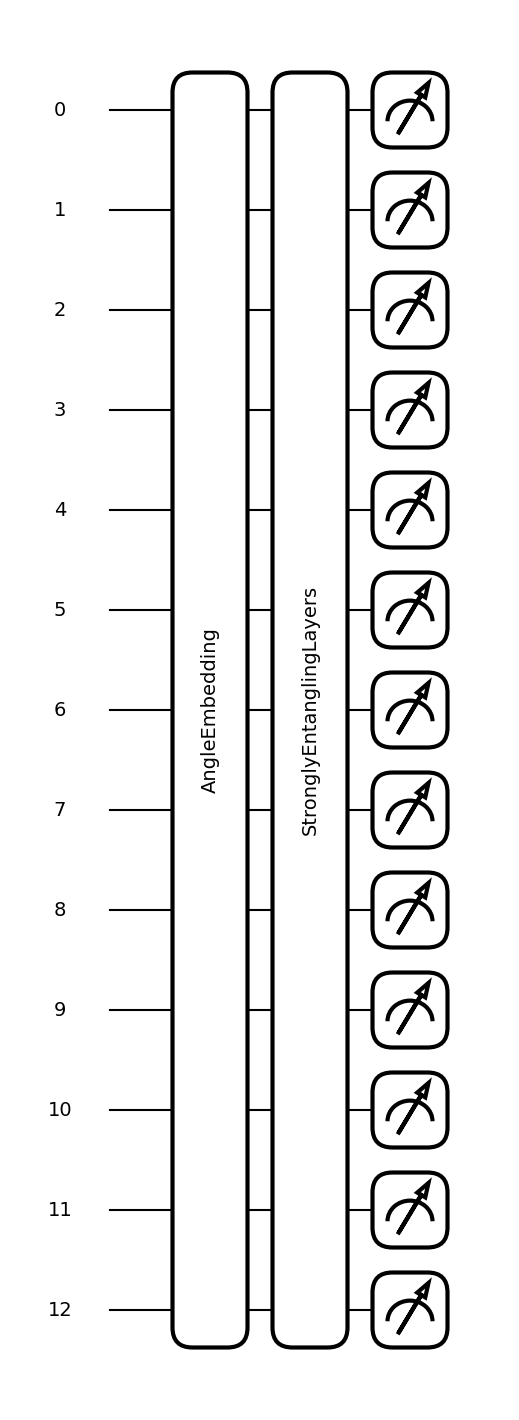

/tmp/ipykernel_8987/2551034382.py:27: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()



Circuit structure with 13 qubits:
 0: ─╭AngleEmbedding(M0)─╭StronglyEntanglingLayers(M1)─┤  <Z>
 1: ─├AngleEmbedding(M0)─├StronglyEntanglingLayers(M1)─┤  <Z>
 2: ─├AngleEmbedding(M0)─├StronglyEntanglingLayers(M1)─┤  <Z>
 3: ─├AngleEmbedding(M0)─├StronglyEntanglingLayers(M1)─┤  <Z>
 4: ─├AngleEmbedding(M0)─├StronglyEntanglingLayers(M1)─┤  <Z>
 5: ─├AngleEmbedding(M0)─├StronglyEntanglingLayers(M1)─┤  <Z>
 6: ─├AngleEmbedding(M0)─├StronglyEntanglingLayers(M1)─┤  <Z>
 7: ─├AngleEmbedding(M0)─├StronglyEntanglingLayers(M1)─┤  <Z>
 8: ─├AngleEmbedding(M0)─├StronglyEntanglingLayers(M1)─┤  <Z>
 9: ─├AngleEmbedding(M0)─├StronglyEntanglingLayers(M1)─┤  <Z>
10: ─├AngleEmbedding(M0)─├StronglyEntanglingLayers(M1)─┤  <Z>
11: ─├AngleEmbedding(M0)─├StronglyEntanglingLayers(M1)─┤  <Z>
12: ─╰AngleEmbedding(M0)─╰StronglyEntanglingLayers(M1)─┤  <Z>

M0 = 
[-1.30810909  0.80632595  0.31006188  0.63272376 -0.33844942 -0.07593564
  0.12321198 -0.01966932  1.59404049 -2.08064878 -0.14620111 -1.51030232
  0.00

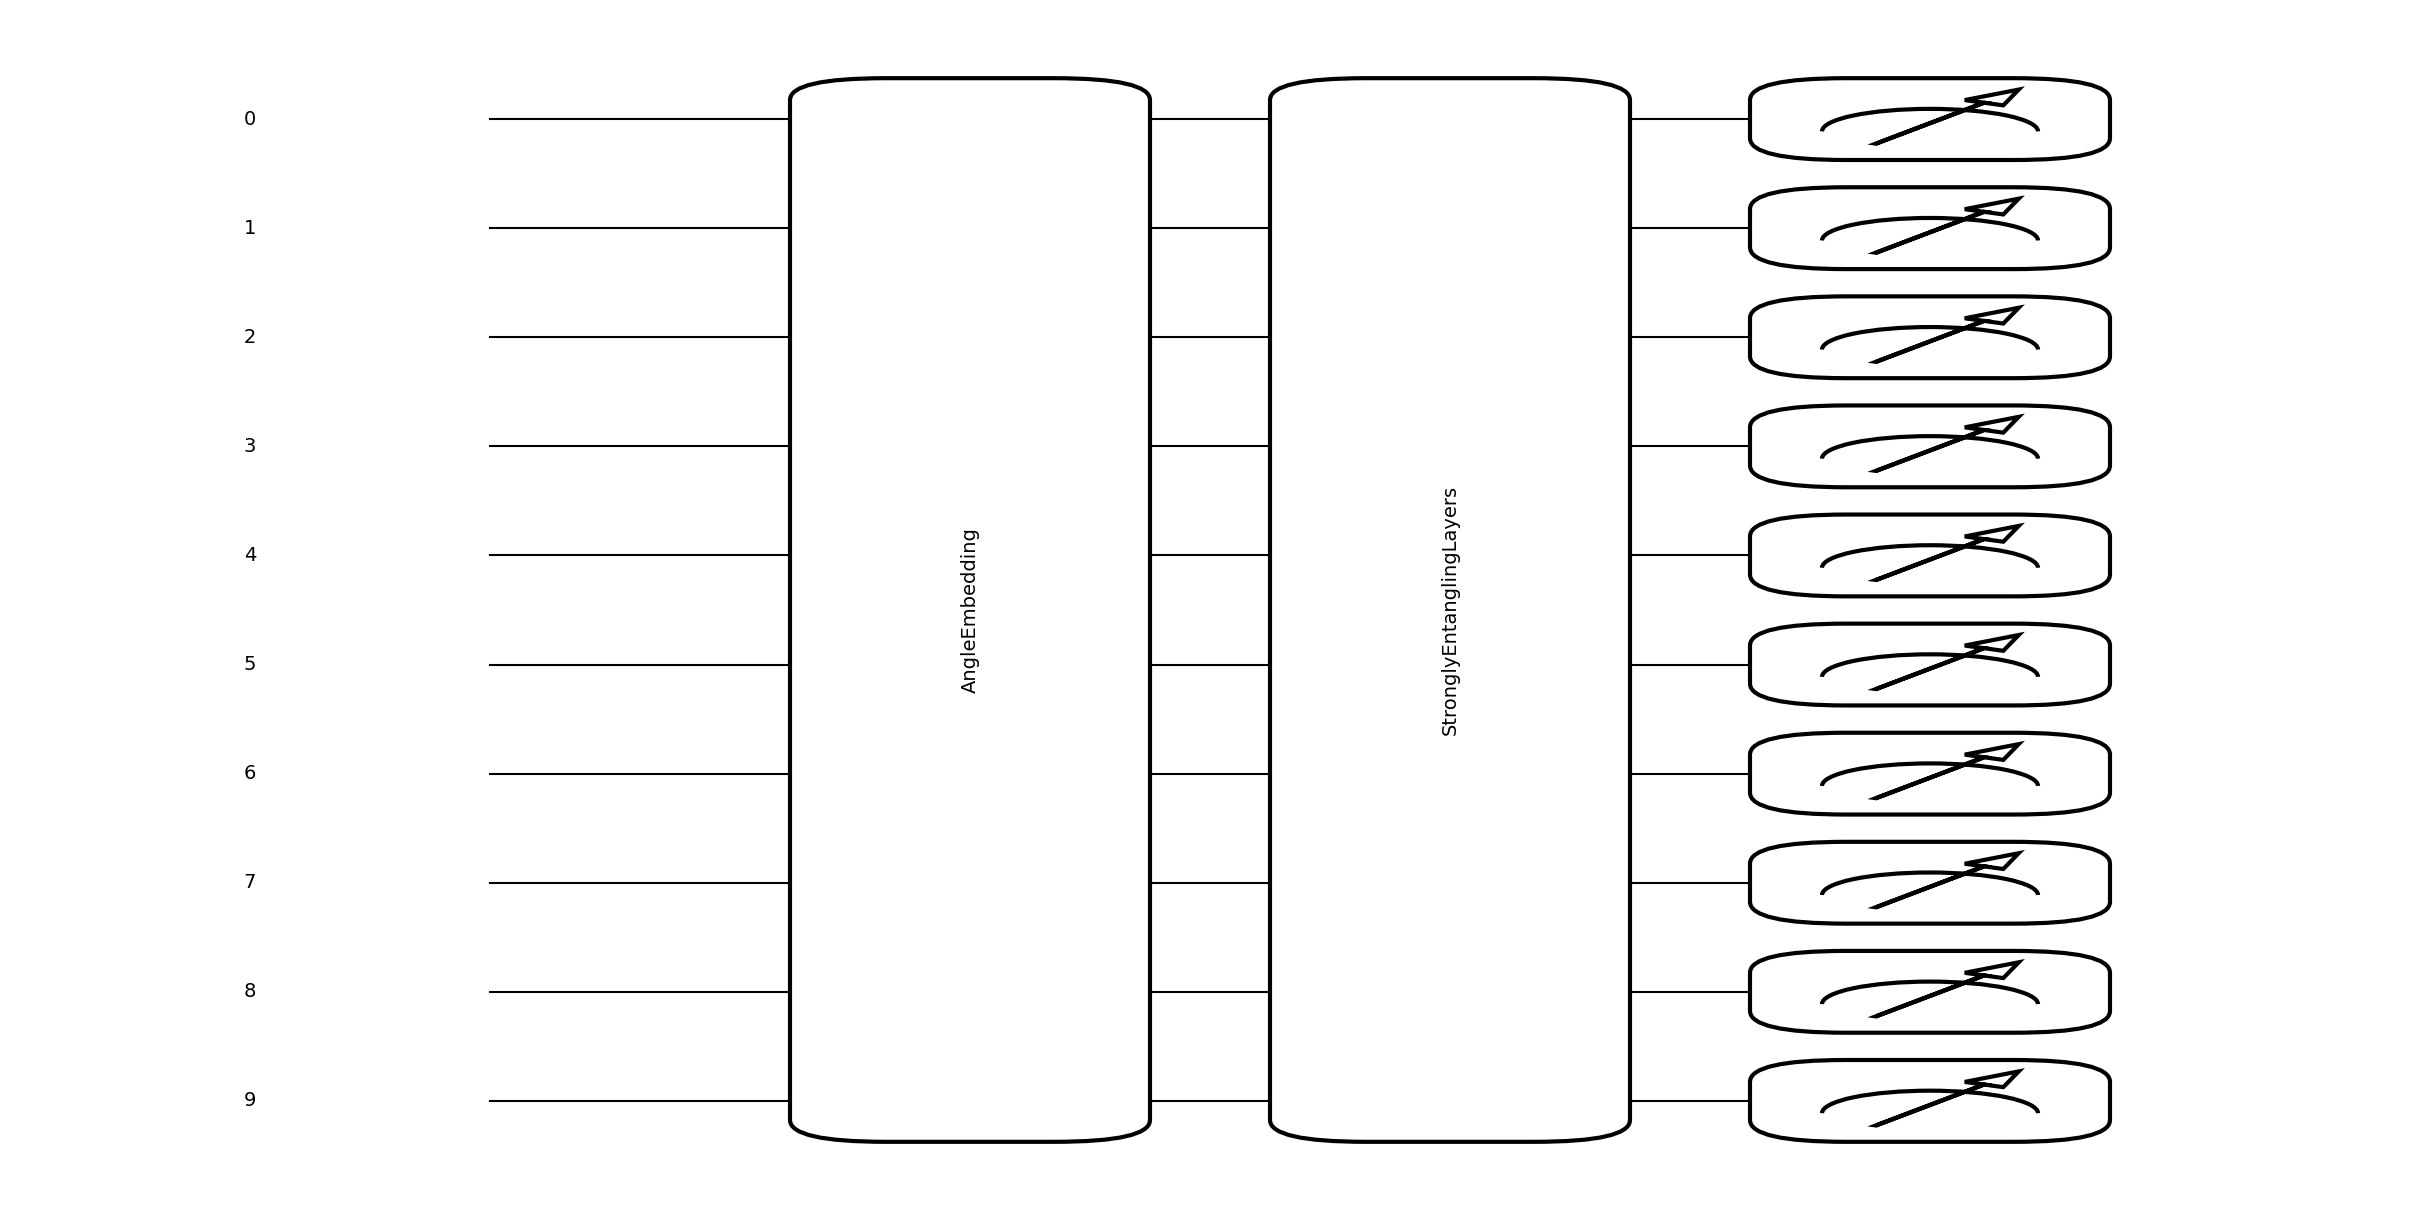

In [ ]:
# import numpy as np

# # Create dummy input and weights just for visualization
# dummy_input = np.random.randn(13)  # 13 features
# dummy_weights = np.random.randn(7, 13, 3)  # 7 layers, 13 qubits, 3 rotations

# # Recreate device and circuit with 13 qubits
# NUM_FEATURES_VIZ = 13
# dev_viz = qml.device("default.qubit", wires=NUM_FEATURES_VIZ)

# @qml.qnode(dev_viz)
# def qnn_circuit_13(inputs, weights):
#     qml.AngleEmbedding(inputs, wires=range(NUM_FEATURES_VIZ))
#     qml.StronglyEntanglingLayers(weights, wires=range(NUM_FEATURES_VIZ))
#     return [qml.expval(qml.PauliZ(i)) for i in range(NUM_FEATURES_VIZ)]

# # Visualize with dummy data
# fig, ax = qml.draw_mpl(qnn_circuit_13, decimals=2)(dummy_input, dummy_weights)
# plt.tight_layout()
# plt.show()
# print("\nCircuit structure with 13 qubits:")
# print(qml.draw(qnn_circuit_13)(dummy_input, dummy_weights))


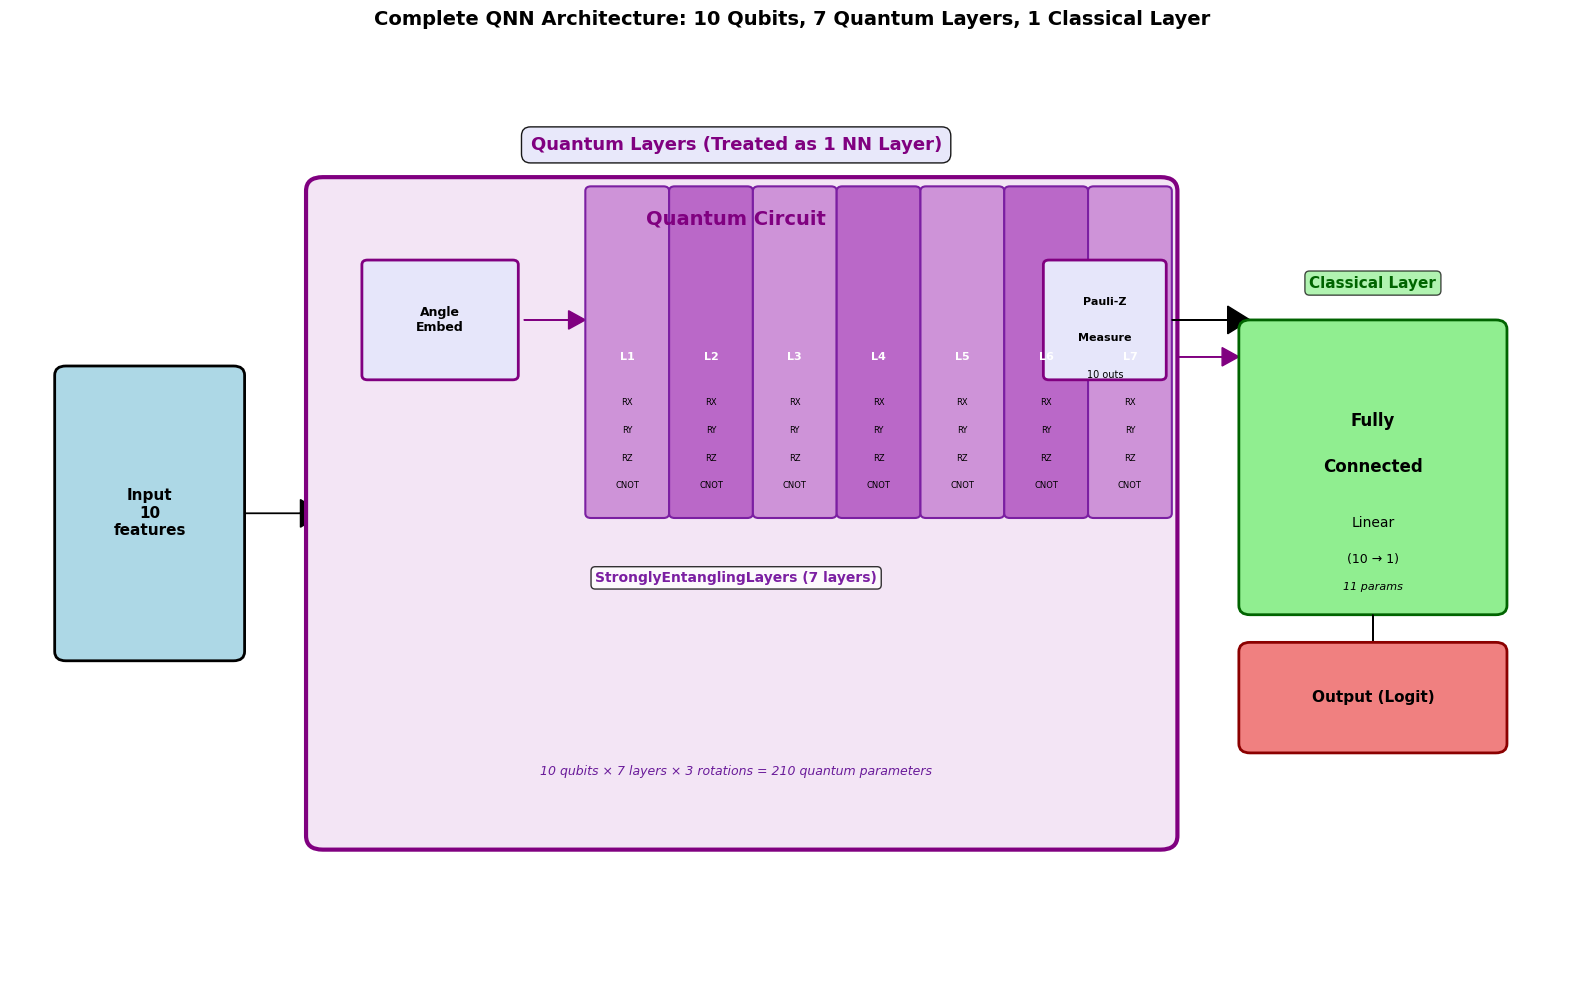

In [ ]:
# import matplotlib.pyplot as plt
# import matplotlib.patches as mpatches
# import numpy as np

# def draw_complete_architecture_with_quantum_layers(n_qubits, n_quantum_layers):
#     """Show quantum layers explicitly"""
    
#     fig, ax = plt.subplots(figsize=(16, 10))
#     ax.set_xlim(0, 14)
#     ax.set_ylim(0, 10)
#     ax.axis('off')
    
#     # Input layer
#     input_box = mpatches.FancyBboxPatch((0.5, 3.5), 1.5, 3, 
#                                          boxstyle="round,pad=0.1", 
#                                          edgecolor='black', facecolor='lightblue', linewidth=2)
#     ax.add_patch(input_box)
#     ax.text(1.25, 5, f'Input\n{n_qubits}\nfeatures', ha='center', va='center', fontsize=11, weight='bold')
    
#     # Arrow
#     ax.arrow(2.1, 5, 0.5, 0, head_width=0.3, head_length=0.2, fc='black', ec='black')
    
#     # Quantum Circuit Box (large)
#     quantum_box = mpatches.FancyBboxPatch((2.8, 1.5), 7.5, 7, 
#                                            boxstyle="round,pad=0.15", 
#                                            edgecolor='purple', facecolor='#F3E5F5', linewidth=3)
#     ax.add_patch(quantum_box)
    
#     # Title for quantum section
#     ax.text(6.5, 8.2, 'Quantum Circuit', ha='center', va='center', 
#            fontsize=14, weight='bold', color='purple')
    
#     # Angle Embedding
#     angle_box = mpatches.FancyBboxPatch((3.2, 6.5), 1.3, 1.2, 
#                                          boxstyle="round,pad=0.05", 
#                                          edgecolor='purple', facecolor='lavender', linewidth=2)
#     ax.add_patch(angle_box)
#     ax.text(3.85, 7.1, 'Angle\nEmbed', ha='center', va='center', fontsize=9, weight='bold')
    
#     ax.arrow(4.6, 7.1, 0.4, 0, head_width=0.2, head_length=0.15, fc='purple', ec='purple')
    
#     # Strongly Entangling Layers (show the 7 layers)
#     layer_width = 0.65
#     layer_height = 3.5
#     start_x = 5.2
    
#     for i in range(n_quantum_layers):
#         x_pos = start_x + i * 0.75
#         layer_box = mpatches.FancyBboxPatch((x_pos, 5), layer_width, layer_height, 
#                                              boxstyle="round,pad=0.05", 
#                                              edgecolor='#7B1FA2', 
#                                              facecolor='#CE93D8' if i % 2 == 0 else '#BA68C8', 
#                                              linewidth=1.5)
#         ax.add_patch(layer_box)
#         ax.text(x_pos + layer_width/2, 6.7, f'L{i+1}', 
#                ha='center', va='center', fontsize=8, weight='bold', color='white')
        
#         # Show gates inside
#         ax.text(x_pos + layer_width/2, 6.2, 'RX', ha='center', va='center', fontsize=6)
#         ax.text(x_pos + layer_width/2, 5.9, 'RY', ha='center', va='center', fontsize=6)
#         ax.text(x_pos + layer_width/2, 5.6, 'RZ', ha='center', va='center', fontsize=6)
#         ax.text(x_pos + layer_width/2, 5.3, 'CNOT', ha='center', va='center', fontsize=6)
    
#     # Label for strongly entangling
#     ax.text(6.5, 4.3, f'StronglyEntanglingLayers ({n_quantum_layers} layers)', 
#            ha='center', va='center', fontsize=10, weight='bold', color='#7B1FA2',
#            bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
    
#     # Arrow
#     ax.arrow(start_x + n_quantum_layers * 0.75, 6.7, 0.4, 0, 
#             head_width=0.2, head_length=0.15, fc='purple', ec='purple')
    
#     # Measurements
#     measure_box = mpatches.FancyBboxPatch((9.3, 6.5), 1.0, 1.2, 
#                                            boxstyle="round,pad=0.05", 
#                                            edgecolor='purple', facecolor='lavender', linewidth=2)
#     ax.add_patch(measure_box)
#     ax.text(9.8, 7.3, 'Pauli-Z', ha='center', va='center', fontsize=8, weight='bold')
#     ax.text(9.8, 6.9, 'Measure', ha='center', va='center', fontsize=8, weight='bold')
#     ax.text(9.8, 6.5, f'{n_qubits} outs', ha='center', va='center', fontsize=7)
    
#     # Info text
#     ax.text(6.5, 2.2, f'{n_qubits} qubits × {n_quantum_layers} layers × 3 rotations = {n_qubits * n_quantum_layers * 3} quantum parameters', 
#            ha='center', va='center', fontsize=9, style='italic', color='#6A1B9A')
    
#     # Arrow out of quantum
#     ax.arrow(10.4, 7.1, 0.5, 0, head_width=0.3, head_length=0.2, fc='black', ec='black')
    
#     # Classical FC Layer
#     fc_box = mpatches.FancyBboxPatch((11.1, 4), 2.2, 3, 
#                                      boxstyle="round,pad=0.1", 
#                                      edgecolor='darkgreen', facecolor='lightgreen', linewidth=2)
#     ax.add_patch(fc_box)
#     ax.text(12.2, 6, 'Fully', ha='center', va='center', fontsize=12, weight='bold')
#     ax.text(12.2, 5.5, 'Connected', ha='center', va='center', fontsize=12, weight='bold')
#     ax.text(12.2, 4.9, f'Linear', ha='center', va='center', fontsize=10)
#     ax.text(12.2, 4.5, f'({n_qubits} → 1)', ha='center', va='center', fontsize=9)
#     ax.text(12.2, 4.2, f'{n_qubits + 1} params', ha='center', va='center', fontsize=8, style='italic')
    
#     # Arrow down
#     ax.arrow(12.2, 3.9, 0, -0.5, head_width=0.3, head_length=0.2, fc='black', ec='black')
    
#     # Output
#     output_box = mpatches.FancyBboxPatch((11.1, 2.5), 2.2, 1, 
#                                          boxstyle="round,pad=0.1", 
#                                          edgecolor='darkred', facecolor='lightcoral', linewidth=2)
#     ax.add_patch(output_box)
#     ax.text(12.2, 3, 'Output (Logit)', ha='center', va='center', fontsize=11, weight='bold')
    
#     # Layer labels
#     ax.text(6.5, 9, 'Quantum Layers (Treated as 1 NN Layer)', 
#            ha='center', va='center', fontsize=13, weight='bold', color='purple',
#            bbox=dict(boxstyle='round', facecolor='lavender', alpha=0.9, pad=0.5))
    
#     ax.text(12.2, 7.5, 'Classical Layer', 
#            ha='center', va='center', fontsize=11, weight='bold', color='darkgreen',
#            bbox=dict(boxstyle='round', facecolor='lightgreen', alpha=0.7))
    
#     plt.title(f'Complete QNN Architecture: {n_qubits} Qubits, {n_quantum_layers} Quantum Layers, 1 Classical Layer', 
#               fontsize=14, weight='bold', pad=20)
#     plt.tight_layout()
#     plt.show()

# # Use it
# draw_complete_architecture_with_quantum_layers(n_qubits=NUM_FEATURES, n_quantum_layers=n_layers)

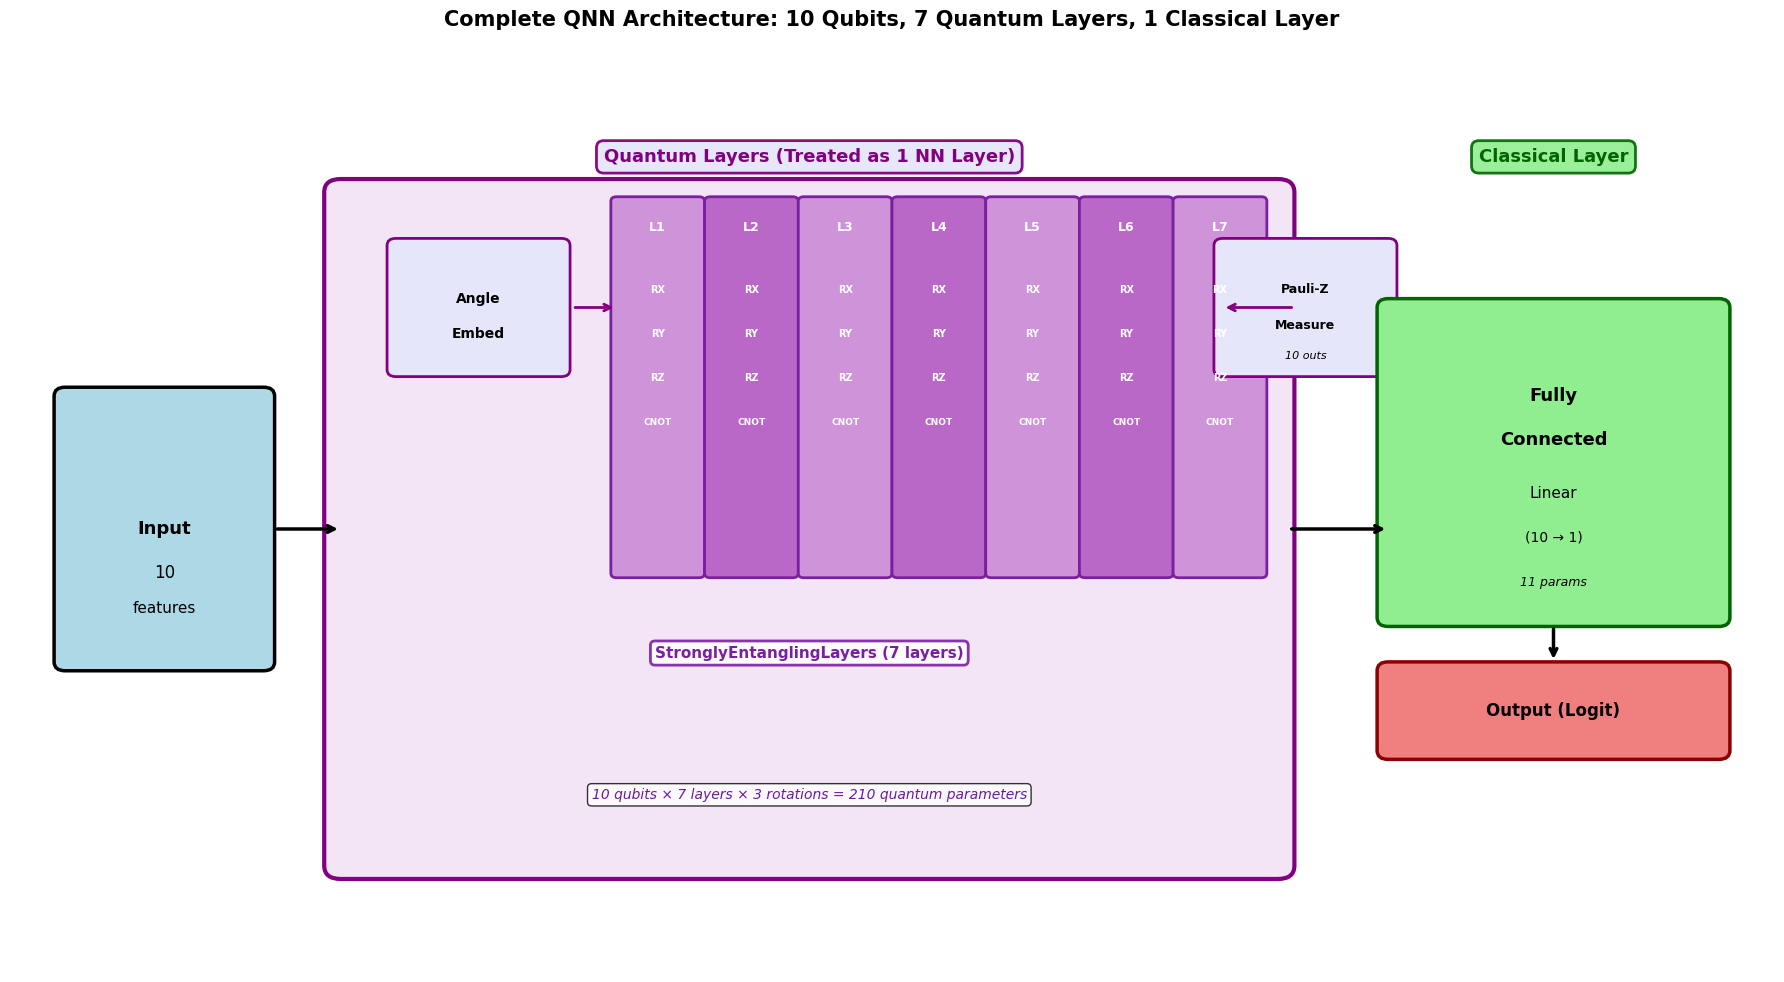

In [ ]:
# import matplotlib.pyplot as plt
# import matplotlib.patches as mpatches
# import numpy as np

# def draw_complete_architecture_with_quantum_layers(n_qubits, n_quantum_layers):
#     """Show quantum layers explicitly with improved alignment"""
    
#     fig, ax = plt.subplots(figsize=(18, 10))
#     ax.set_xlim(0, 16)
#     ax.set_ylim(0, 10)
#     ax.axis('off')
    
#     # Input layer
#     input_box = mpatches.FancyBboxPatch((0.5, 3.5), 1.8, 3, 
#                                          boxstyle="round,pad=0.1", 
#                                          edgecolor='black', facecolor='lightblue', linewidth=2.5)
#     ax.add_patch(input_box)
#     ax.text(1.4, 5, f'Input', ha='center', va='center', fontsize=13, weight='bold')
#     ax.text(1.4, 4.5, f'{n_qubits}', ha='center', va='center', fontsize=12)
#     ax.text(1.4, 4.1, f'features', ha='center', va='center', fontsize=11)
    
#     # Arrow to quantum
#     ax.annotate('', xy=(3.0, 5), xytext=(2.4, 5),
#                 arrowprops=dict(arrowstyle='->', lw=2.5, color='black'))
    
#     # Quantum Circuit Box (large)
#     quantum_box = mpatches.FancyBboxPatch((3.0, 1.2), 8.5, 7.6, 
#                                            boxstyle="round,pad=0.15", 
#                                            edgecolor='purple', facecolor='#F3E5F5', linewidth=3)
#     ax.add_patch(quantum_box)
    
#     # Title for quantum section at the top
#     ax.text(7.25, 9.2, 'Quantum Layers (Treated as 1 NN Layer)', 
#            ha='center', va='center', fontsize=13, weight='bold', color='purple',
#            bbox=dict(boxstyle='round,pad=0.4', facecolor='lavender', 
#                     edgecolor='purple', linewidth=2, alpha=0.95))
    
#     # Angle Embedding
#     angle_box = mpatches.FancyBboxPatch((3.5, 6.8), 1.5, 1.4, 
#                                          boxstyle="round,pad=0.08", 
#                                          edgecolor='purple', facecolor='lavender', linewidth=2)
#     ax.add_patch(angle_box)
#     ax.text(4.25, 7.6, 'Angle', ha='center', va='center', fontsize=10, weight='bold')
#     ax.text(4.25, 7.2, 'Embed', ha='center', va='center', fontsize=10, weight='bold')
    
#     # Arrow from angle embedding to layers
#     ax.annotate('', xy=(5.5, 7.5), xytext=(5.1, 7.5),
#                 arrowprops=dict(arrowstyle='->', lw=2, color='purple'))
    
#     # Strongly Entangling Layers (show the 7 layers)
#     layer_width = 0.75
#     layer_height = 4.2
#     start_x = 5.5
#     start_y = 4.5
    
#     for i in range(n_quantum_layers):
#         x_pos = start_x + i * 0.85
#         layer_box = mpatches.FancyBboxPatch((x_pos, start_y), layer_width, layer_height, 
#                                              boxstyle="round,pad=0.05", 
#                                              edgecolor='#7B1FA2', 
#                                              facecolor='#CE93D8' if i % 2 == 0 else '#BA68C8', 
#                                              linewidth=2)
#         ax.add_patch(layer_box)
        
#         # Layer label at top
#         ax.text(x_pos + layer_width/2, start_y + layer_height - 0.3, f'L{i+1}', 
#                ha='center', va='center', fontsize=9, weight='bold', color='white')
        
#         # Show gates inside - evenly spaced
#         gate_y_start = start_y + layer_height - 1.0
#         ax.text(x_pos + layer_width/2, gate_y_start, 'RX', 
#                ha='center', va='center', fontsize=7, color='white', weight='bold')
#         ax.text(x_pos + layer_width/2, gate_y_start - 0.5, 'RY', 
#                ha='center', va='center', fontsize=7, color='white', weight='bold')
#         ax.text(x_pos + layer_width/2, gate_y_start - 1.0, 'RZ', 
#                ha='center', va='center', fontsize=7, color='white', weight='bold')
#         ax.text(x_pos + layer_width/2, gate_y_start - 1.5, 'CNOT', 
#                ha='center', va='center', fontsize=6.5, color='white', weight='bold')
    
#     # Label for strongly entangling - below the layers
#     ax.text(7.25, 3.6, f'StronglyEntanglingLayers ({n_quantum_layers} layers)', 
#            ha='center', va='center', fontsize=11, weight='bold', color='#7B1FA2',
#            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', 
#                     edgecolor='#7B1FA2', linewidth=2, alpha=0.9))
    
#     # Arrow from layers to measurements
#     ax.annotate('', xy=(11.0, 7.5), xytext=(start_x + n_quantum_layers * 0.85 + 0.2, 7.5),
#                 arrowprops=dict(arrowstyle='->', lw=2, color='purple'))
    
#     # Measurements - aligned with angle embedding
#     measure_box = mpatches.FancyBboxPatch((11.0, 6.8), 1.5, 1.4, 
#                                            boxstyle="round,pad=0.08", 
#                                            edgecolor='purple', facecolor='lavender', linewidth=2)
#     ax.add_patch(measure_box)
#     ax.text(11.75, 7.7, 'Pauli-Z', ha='center', va='center', fontsize=9, weight='bold')
#     ax.text(11.75, 7.3, 'Measure', ha='center', va='center', fontsize=9, weight='bold')
#     ax.text(11.75, 6.95, f'{n_qubits} outs', ha='center', va='center', fontsize=8, style='italic')
    
#     # Info text - centered below layers
#     ax.text(7.25, 2.0, 
#            f'{n_qubits} qubits × {n_quantum_layers} layers × 3 rotations = {n_qubits * n_quantum_layers * 3} quantum parameters', 
#            ha='center', va='center', fontsize=10, style='italic', color='#6A1B9A',
#            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8))
    
#     # Arrow out of quantum to classical
#     ax.annotate('', xy=(12.5, 5), xytext=(11.6, 5),
#                 arrowprops=dict(arrowstyle='->', lw=2.5, color='black'))
    
#     # Classical Layer label at top
#     ax.text(14.0, 9.2, 'Classical Layer', 
#            ha='center', va='center', fontsize=13, weight='bold', color='darkgreen',
#            bbox=dict(boxstyle='round,pad=0.4', facecolor='lightgreen', 
#                     edgecolor='darkgreen', linewidth=2, alpha=0.9))
    
#     # Classical FC Layer - aligned with quantum box
#     fc_box = mpatches.FancyBboxPatch((12.5, 4), 3.0, 3.5, 
#                                      boxstyle="round,pad=0.1", 
#                                      edgecolor='darkgreen', facecolor='lightgreen', linewidth=2.5)
#     ax.add_patch(fc_box)
#     ax.text(14.0, 6.5, 'Fully', ha='center', va='center', fontsize=13, weight='bold')
#     ax.text(14.0, 6.0, 'Connected', ha='center', va='center', fontsize=13, weight='bold')
#     ax.text(14.0, 5.4, 'Linear', ha='center', va='center', fontsize=11)
#     ax.text(14.0, 4.9, f'({n_qubits} → 1)', ha='center', va='center', fontsize=10)
#     ax.text(14.0, 4.4, f'{n_qubits + 1} params', ha='center', va='center', fontsize=9, style='italic')
    
#     # Arrow down to output
#     ax.annotate('', xy=(14.0, 3.5), xytext=(14.0, 3.9),
#                 arrowprops=dict(arrowstyle='->', lw=2.5, color='black'))
    
#     # Output - aligned with FC layer
#     output_box = mpatches.FancyBboxPatch((12.5, 2.5), 3.0, 0.9, 
#                                          boxstyle="round,pad=0.1", 
#                                          edgecolor='darkred', facecolor='lightcoral', linewidth=2.5)
#     ax.add_patch(output_box)
#     ax.text(14.0, 2.95, 'Output (Logit)', ha='center', va='center', fontsize=12, weight='bold')
    
#     # Overall title
#     plt.suptitle(f'Complete QNN Architecture: {n_qubits} Qubits, {n_quantum_layers} Quantum Layers, 1 Classical Layer', 
#               fontsize=15, weight='bold', y=0.98)
    
#     plt.tight_layout(rect=[0, 0, 1, 0.96])
#     plt.show()

# # Use it
# draw_complete_architecture_with_quantum_layers(n_qubits=NUM_FEATURES, n_quantum_layers=n_layers)

In [22]:
qnn_model = model
qsvm_preds = all_test_preds
X_meta = np.vstack([qsvm_preds, qnn_preds]).T  # shape: (n_samples, 2)
from sklearn.ensemble import RandomForestClassifier

# Initialize and train the meta-model
meta_model_rf = RandomForestClassifier(n_estimators=100, random_state=42)
meta_model_rf.fit(X_meta, y_test[:1000])  # match y_test slicing
ensemble_rf_preds = meta_model_rf.predict(X_meta)

print("Random Forest Meta-Model Accuracy:", accuracy_score(y_test[:1000], ensemble_rf_preds))
print("\nClassification Report (Random Forest Meta-Model):")
print(classification_report(y_test[:1000], ensemble_rf_preds))


Random Forest Meta-Model Accuracy: 0.994

Classification Report (Random Forest Meta-Model):
              precision    recall  f1-score   support

           0       0.99      0.98      0.99       252
           1       0.99      1.00      1.00       748

    accuracy                           0.99      1000
   macro avg       0.99      0.99      0.99      1000
weighted avg       0.99      0.99      0.99      1000



In [24]:
f3 = f1_score(y_test[:1000], ensemble_rf_preds)

print(f"F1 score RF Ensemble: {f3:.4f}")

F1 score RF Ensemble: 0.9960


In [23]:
auprc_rf = average_precision_score(y_test[:1000], ensemble_rf_preds)

print(f"AUPRC RF Ensemble: {auprc_rf:.4f}")

AUPRC RF Ensemble: 0.9940


In [29]:
print("\n==============================")
print("🚀 DRIFT DETECTION MODULE")
print("==============================\n")

# ------------------------------------------------------------
# 1. Extract a fixed training reference window
# ------------------------------------------------------------
# Use the same kernel you saved during training
K_ref = K_train_4.copy()
y_ref = train_batches[4][1]   # labels of batch 5 (index 4)

print(f"Reference window size: {K_ref.shape}")

# ------------------------------------------------------------
# 2. QSVM prediction function (PRECOMPUTED KERNEL)
# ------------------------------------------------------------
def predict_qsvm_precomputed(model, K):
    return model.predict(K)

# ------------------------------------------------------------
# 3. Build PRE and POST kernel matrices relative to reference
# ------------------------------------------------------------
# Pre-drift → first half of batch 5 test set
X_test_4, y_test_4 = test_batches[4]

mid = len(X_test_4) // 2
X_pre  = X_test_4[:mid]
y_pre  = y_test_4[:mid]
X_post = X_test_4[mid:]
y_post = y_test_4[mid:]

# Build precomputed kernels
def build_kernel_against_reference(X_segment, X_reference):
    K = np.zeros((len(X_segment), len(X_reference)))
    for i in range(len(X_segment)):
        for j in range(len(X_reference)):
            probs = kernel_circuit(X_segment[i], X_reference[j])
            K[i, j] = probs[0]
    return K

print("- Building pre-drift kernel...")
K_pre = build_kernel_against_reference(X_pre,  X_batch_train)

print("- Building post-drift kernel...")
K_post = build_kernel_against_reference(X_post, X_batch_train)

# ------------------------------------------------------------
# 4. Run predictions from already-trained QSVM
# ------------------------------------------------------------
print("- Predicting pre-drift...")
pre_preds = predict_qsvm_precomputed(best_model, K_pre)

print("- Predicting post-drift...")
post_preds = predict_qsvm_precomputed(best_model, K_post)

# ------------------------------------------------------------
# 5. Compute accuracy drop = DRIFT SIGNAL
# ------------------------------------------------------------
from sklearn.metrics import accuracy_score

acc_pre  = accuracy_score(y_pre,  pre_preds)
acc_post = accuracy_score(y_post, post_preds)

print("\n==============================")
print("📉 DRIFT DETECTION RESULTS")
print("==============================")
print(f"Pre-Drift Accuracy : {acc_pre:.4f}")
print(f"Post-Drift Accuracy: {acc_post:.4f}")
print(f"Accuracy Drop      : {acc_pre - acc_post:.4f}")

if acc_pre - acc_post > 0.10:
    print("\n⚠️ Significant drift detected (>10% performance drop)")
else:
    print("\nNo significant drift detected.")



🚀 DRIFT DETECTION MODULE

Reference window size: (300, 300)
- Building pre-drift kernel...
- Building post-drift kernel...
- Predicting pre-drift...
- Predicting post-drift...

📉 DRIFT DETECTION RESULTS
Pre-Drift Accuracy : 0.9800
Post-Drift Accuracy: 0.9800
Accuracy Drop      : 0.0000

No significant drift detected.


In [28]:
print(best_model.__class__)
print(best_model.__dict__.keys())


<class 'sklearn.svm._classes.SVC'>
dict_keys(['decision_function_shape', 'break_ties', 'kernel', 'degree', 'gamma', 'coef0', 'tol', 'C', 'nu', 'epsilon', 'shrinking', 'probability', 'cache_size', 'class_weight', 'verbose', 'max_iter', 'random_state', '_sparse', 'n_features_in_', 'class_weight_', 'classes_', '_gamma', 'support_', 'support_vectors_', '_n_support', 'dual_coef_', 'intercept_', '_probA', '_probB', 'fit_status_', '_num_iter', 'shape_fit_', '_intercept_', '_dual_coef_', 'n_iter_'])


In [30]:
print("\n===== PCA DETAILS =====")
print("Number of components:", pca.n_components_)
print("Explained variance per component:", pca.explained_variance_ratio_)
print("Total explained variance:", pca.explained_variance_ratio_.sum())
print("PCA Singular Values:", pca.singular_values_)


===== PCA DETAILS =====
Number of components: 13
Explained variance per component: [0.13782949 0.13405627 0.08778428 0.05063025 0.04917859 0.04513258
 0.04365054 0.04212232 0.03905491 0.03675613 0.03087553 0.02546804
 0.02376307]
Total explained variance: 0.7463019751281674
PCA Singular Values: [1000.31149559  986.52419963  798.31183743  606.27437163  597.51966893
  572.41267811  562.93593982  552.99385761  532.47842617  516.56984533
  473.44700423  429.99351343  415.35116112]


In [31]:
print("\n===== QSVM (SVC) DETAILS =====")
for param, value in best_model.get_params().items():
    print(f"{param}: {value}")

print("\n--- Support Vectors Info ---")
print("Number of support vectors:", best_model.n_support_)
print("Total support vectors:", len(best_model.support_))

print("\n--- SVM Fit Info ---")
print("Classes:", best_model.classes_)
print("Kernel type:", best_model.kernel)
print("C:", best_model.C)
print("Tolerance (tol):", best_model.tol)
print("Gamma:", best_model.gamma)
print("Degree (if polynomial kernel):", best_model.degree)



===== QSVM (SVC) DETAILS =====
C: 10
break_ties: False
cache_size: 200
class_weight: None
coef0: 0.0
decision_function_shape: ovr
degree: 3
gamma: scale
kernel: precomputed
max_iter: -1
probability: False
random_state: None
shrinking: True
tol: 0.001
verbose: False

--- Support Vectors Info ---
Number of support vectors: [24 16]
Total support vectors: 40

--- SVM Fit Info ---
Classes: [0 1]
Kernel type: precomputed
C: 10
Tolerance (tol): 0.001
Gamma: scale
Degree (if polynomial kernel): 3


In [33]:
print("\n===== RANDOM FOREST DETAILS =====")
for param, value in meta_model_rf.get_params().items():
    print(f"{param}: {value}")

print("\n--- Important Parameters ---")
print("n_estimators:", meta_model_rf.n_estimators)
print("max_depth:", meta_model_rf.max_depth)
print("min_samples_leaf:", meta_model_rf.min_samples_leaf)
print("class_weight:", meta_model_rf.class_weight)
print("max_features:", meta_model_rf.max_features)

print("\nFeature Importance (top 10):")
import numpy as np
idx = np.argsort(meta_model_rf.feature_importances_)[::-1][:10]
print(idx)
print(meta_model_rf.feature_importances_[idx])



===== RANDOM FOREST DETAILS =====
bootstrap: True
ccp_alpha: 0.0
class_weight: None
criterion: gini
max_depth: None
max_features: sqrt
max_leaf_nodes: None
max_samples: None
min_impurity_decrease: 0.0
min_samples_leaf: 1
min_samples_split: 2
min_weight_fraction_leaf: 0.0
monotonic_cst: None
n_estimators: 100
n_jobs: None
oob_score: False
random_state: 42
verbose: 0
warm_start: False

--- Important Parameters ---
n_estimators: 100
max_depth: None
min_samples_leaf: 1
class_weight: None
max_features: sqrt

Feature Importance (top 10):
[1 0]
[0.56793736 0.43206264]


Min FPR: 0.0
Max FPR: 1.0


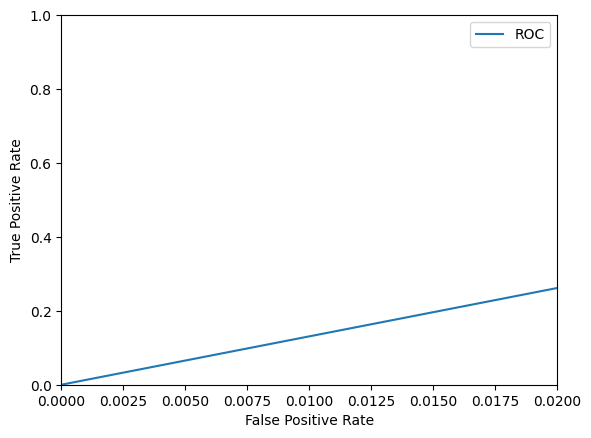

{'TPR@0.1%FPR': 0.01308584294962004, 'TPR@1.0%FPR': 0.13085842949620038}


In [ ]:
metrics = compute_tpr_at_fpr(y_test[:1000], ensemble_rf_preds)
print(metrics)

In [ ]:
from joblib import dump, load

dump(meta_model_rf, 'final_model(13).joblib')



['final_model(13).joblib']

In [ ]:
model = load('final_model(13).joblib')
ensemble_rf_preds = model.predict(X_meta)
print("Random Forest Meta-Model Accuracy:", accuracy_score(y_test[:1000], ensemble_rf_preds))
print("\nClassification Report (Random Forest Meta-Model):")
print(classification_report(y_test[:1000], ensemble_rf_preds))

Random Forest Meta-Model Accuracy: 0.971

Classification Report (Random Forest Meta-Model):
              precision    recall  f1-score   support

           0       0.96      0.92      0.94       252
           1       0.97      0.99      0.98       748

    accuracy                           0.97      1000
   macro avg       0.97      0.96      0.96      1000
weighted avg       0.97      0.97      0.97      1000



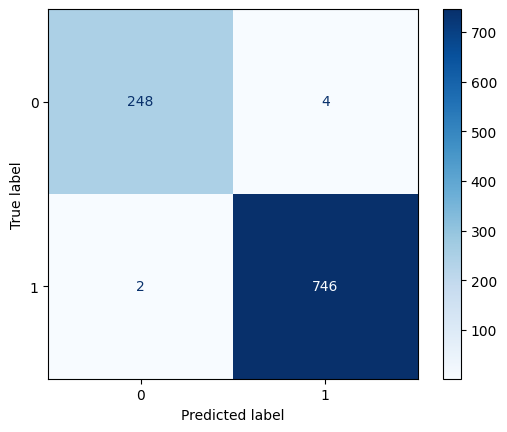

In [24]:
# CM for RFMM

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Compute confusion matrix
cm = confusion_matrix(y_test[:1000], ensemble_rf_preds)


# Display
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap="Blues", values_format="d")
# plt.title("Confusion Matrix - Random Forest Meta Model")
plt.show()

In [ ]:
full_model = {
    "qsvm": grid,                  
    "qnn": qnn_model,              
    "meta_model": meta_model_rf,      
    "label_encoders": label_encoders, 
    "scaler": scaler,                 
    "pca": pca,
    "feature_columns": list(feature_names)  
}

import joblib
joblib.dump(full_model, "quantum_meta_model.joblib")


['quantum_meta_model.joblib']

In [ ]:
from ptflops import get_model_complexity_info
import torch

# FLOPs for QNN
dummy_input = torch.rand(1, X_train.shape[1])  # 1 sample with correct feature size
flops, params = get_model_complexity_info(qnn_model, (X_train.shape[1],), verbose=False)

print(f"QNN FLOPs: {flops}, Params: {params}")


QNNClassifier(
  11, 4.977% Params, 11.0 Mac, 100.000% MACs, 
  (qlayer): <Quantum Torch Layer: func=qnn_circuit>
  (fc): Linear(11, 4.977% Params, 11.0 Mac, 100.000% MACs, in_features=10, out_features=1, bias=True)
)
QNN FLOPs: 11 Mac, Params: 221


In [ ]:
def estimate_rf_flops(model, num_features, num_samples):
    """
    Rough estimate FLOPs for Random Forest:
    - Each decision tree: O(depth * num_samples)
    - Multiply by number of trees
    """
    avg_depth = sum(estimator.tree_.max_depth for estimator in model.estimators_) / len(model.estimators_)
    flops = len(model.estimators_) * avg_depth * num_samples * num_features
    return flops

rf_flops = estimate_rf_flops(meta_model_rf, num_features=2, num_samples=len(X_test))  # 2 features = QSVM+QNN outputs
print(f"Estimated RF FLOPs: {rf_flops}")


Estimated RF FLOPs: 16883600.0


In [ ]:
def estimate_qsvm_flops(num_features, num_samples, num_batches):
    """
    Approx FLOPs for QSVM = O(N^2 * feature_map_cost)
    - num_features: features in each input vector
    - num_samples: number of training samples per batch
    - num_batches: number of batches QSVM was trained on
    """
    # Rough estimate: each kernel evaluation ~ O(num_features^2)
    feature_map_cost = num_features ** 2
    per_batch_flops = (num_samples ** 2) * feature_map_cost
    total_flops = num_batches * per_batch_flops
    return total_flops

# Example usage with your dataset
qsvm_flops = estimate_qsvm_flops(X_train.shape[1], len(X_train)//10, 10)  # since 10 batches
print(f"Estimated QSVM FLOPs: {qsvm_flops}")


Estimated QSVM FLOPs: 285035689000


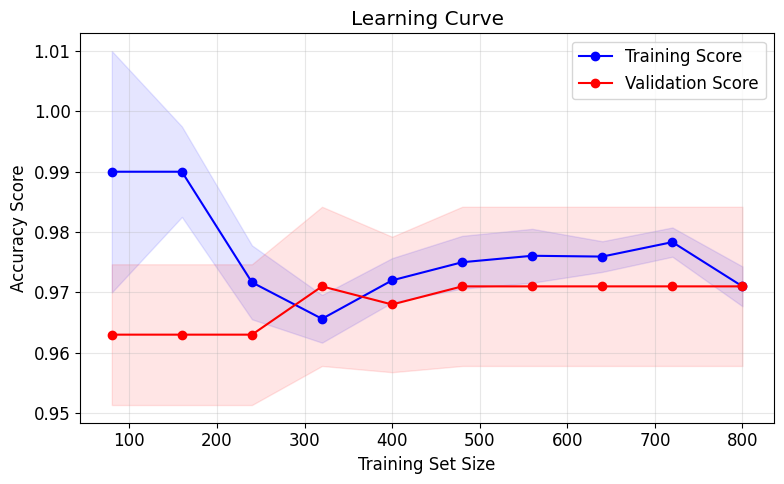

Final Training Score: 0.9710 (±0.0033)
Final Validation Score: 0.9710 (±0.0132)

Model Analysis:
Model appears well-balanced (gap: 0.0000)


In [ ]:
# from sklearn.model_selection import learning_curve
# import matplotlib.pyplot as plt
# import numpy as np
# plt.rcParams.update({'font.size': 12})
# # Generate learning curve for Random Forest meta-model
# def plot_learning_curve(estimator, X, y, title="Learning Curve", cv=5, 
#                        train_sizes=np.linspace(0.1, 1.0, 10)):
#     """
#     Generate and plot learning curve for a model
#     """
#     train_sizes, train_scores, val_scores = learning_curve(
#         estimator, X, y, cv=cv, train_sizes=train_sizes, 
#         scoring='accuracy', n_jobs=-1, random_state=42
#     )
    
#     # Calculate mean and std
#     train_mean = np.mean(train_scores, axis=1)
#     train_std = np.std(train_scores, axis=1)
#     val_mean = np.mean(val_scores, axis=1)
#     val_std = np.std(val_scores, axis=1)
    
#     # Plot learning curve
#     # plt.figure(figsize=(10, 6))
#     plt.figure(figsize=(8, 5))
#     plt.plot(train_sizes, train_mean, 'o-', color='blue', label='Training Score')
#     plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, 
#                      alpha=0.1, color='blue')
    
#     plt.plot(train_sizes, val_mean, 'o-', color='red', label='Validation Score')
#     plt.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, 
#                      alpha=0.1, color='red')
    
#     plt.xlabel('Training Set Size')
#     plt.ylabel('Accuracy Score')
#     plt.title(title)
#     plt.legend(loc='best')
#     plt.grid(True, alpha=0.3)
#     plt.tight_layout()
#     plt.show()
    
#     # Print final scores
#     print(f"Final Training Score: {train_mean[-1]:.4f} (±{train_std[-1]:.4f})")
#     print(f"Final Validation Score: {val_mean[-1]:.4f} (±{val_std[-1]:.4f})")
    
#     return train_sizes, train_scores, val_scores

# # Plot learning curve for Random Forest meta-model
# train_sizes, train_scores, val_scores = plot_learning_curve(
#     meta_model_rf, X_meta, y_test[:1000], 
#     # title="Learning Curve - Random Forest Meta-Model",
#     cv=5
# )

# # Additional analysis: Check for overfitting/underfitting
# final_train_mean = np.mean(train_scores, axis=1)[-1]
# final_val_mean = np.mean(val_scores, axis=1)[-1]
# gap = final_train_mean - final_val_mean

# print(f"\nModel Analysis:")
# if gap > 0.05:
#     print(f"Potential overfitting detected (gap: {gap:.4f})")
# elif final_val_mean < 0.7:
#     print(f"Potential underfitting detected (validation score: {final_val_mean:.4f})")
# else:
#     print(f"Model appears well-balanced (gap: {gap:.4f})")

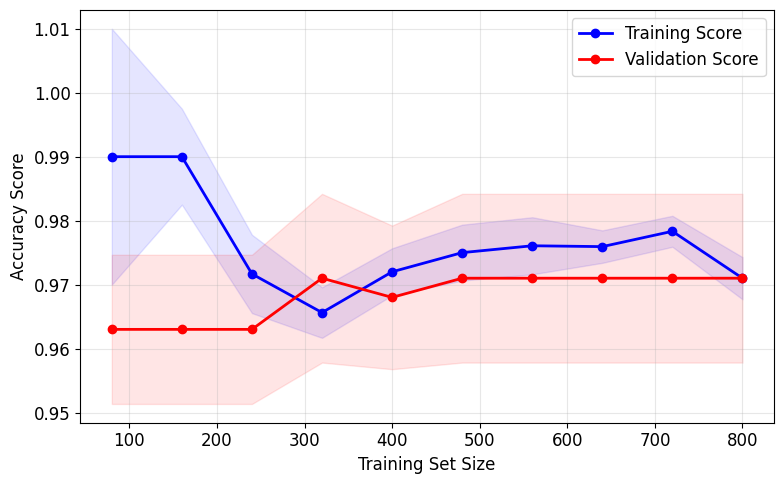

Final Training Score: 0.9710 (±0.0033)
Final Validation Score: 0.9710 (±0.0132)

Model Analysis:
Model appears well-balanced (gap: 0.0000)


In [ ]:
# from sklearn.model_selection import learning_curve
# import matplotlib.pyplot as plt
# import numpy as np

# # Generate learning curve for Random Forest meta-model
# def plot_learning_curve(estimator, X, y, cv=5, 
#                        train_sizes=np.linspace(0.1, 1.0, 10)):
#     """
#     Generate and plot learning curve for a model
#     """
#     train_sizes, train_scores, val_scores = learning_curve(
#         estimator, X, y, cv=cv, train_sizes=train_sizes, 
#         scoring='accuracy', n_jobs=-1, random_state=42
#     )
    
#     # Calculate mean and std
#     train_mean = np.mean(train_scores, axis=1)
#     train_std = np.std(train_scores, axis=1)
#     val_mean = np.mean(val_scores, axis=1)
#     val_std = np.std(val_scores, axis=1)
    
#     # Plot learning curve
#     plt.figure(figsize=(8, 5))
#     plt.plot(train_sizes, train_mean, 'o-', color='blue', label='Training Score', linewidth=2, markersize=6)
#     plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, 
#                      alpha=0.1, color='blue')
    
#     plt.plot(train_sizes, val_mean, 'o-', color='red', label='Validation Score', linewidth=2, markersize=6)
#     plt.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, 
#                      alpha=0.1, color='red')
    
#     plt.xlabel('Training Set Size', fontsize=12)
#     plt.ylabel('Accuracy Score', fontsize=12)
#     # Title removed as requested
#     plt.legend(loc='best', fontsize=12)
#     plt.grid(True, alpha=0.3)
#     plt.tick_params(axis='both', which='major', labelsize=12)
#     plt.tight_layout()
#     plt.show()
    
#     # Print final scores
#     print(f"Final Training Score: {train_mean[-1]:.4f} (±{train_std[-1]:.4f})")
#     print(f"Final Validation Score: {val_mean[-1]:.4f} (±{val_std[-1]:.4f})")
    
#     return train_sizes, train_scores, val_scores

# # Plot learning curve for Random Forest meta-model
# train_sizes, train_scores, val_scores = plot_learning_curve(
#     meta_model_rf, X_meta, y_test[:1000], 
#     cv=5
# )

# # Additional analysis: Check for overfitting/underfitting
# final_train_mean = np.mean(train_scores, axis=1)[-1]
# final_val_mean = np.mean(val_scores, axis=1)[-1]
# gap = final_train_mean - final_val_mean

# print(f"\nModel Analysis:")
# if gap > 0.05:
#     print(f"Potential overfitting detected (gap: {gap:.4f})")
# elif final_val_mean < 0.7:
#     print(f"Potential underfitting detected (validation score: {final_val_mean:.4f})")
# else:
#     print(f"Model appears well-balanced (gap: {gap:.4f})")

In [ ]:
# True labels
y_true = y_test[:1000]

# Error indices
E_qsvm = np.where(qsvm_preds != y_true)[0]
E_qnn  = np.where(qnn_preds != y_true)[0]
E_int  = np.intersect1d(E_qsvm, E_qnn)

print("Errors - QSVM:", len(E_qsvm))
print("Errors - QNN :", len(E_qnn))
print("Errors - Both:", len(E_int))

Errors - QSVM: 29
Errors - QNN : 40
Errors - Both: 19


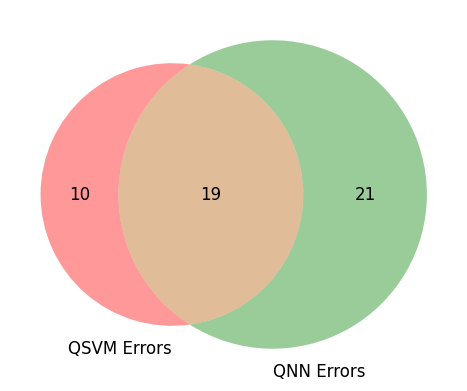

In [ ]:
# from matplotlib_venn import venn2

# v=venn2(
#     subsets = (
#         len(E_qsvm) - len(E_int),
#         len(E_qnn) - len(E_int),
#         len(E_int)
#     ),
#     set_labels = ("QSVM Errors", "QNN Errors")
# )

# # Set fontsize for set labels
# for text in v.set_labels:
#     text.set_fontsize(12)

# # Set fontsize for subset labels (numbers inside circles)
# for text in v.subset_labels:
#     text.set_fontsize(12)

# # plt.title("Error Overlap (Venn Diagram)")
# plt.show()


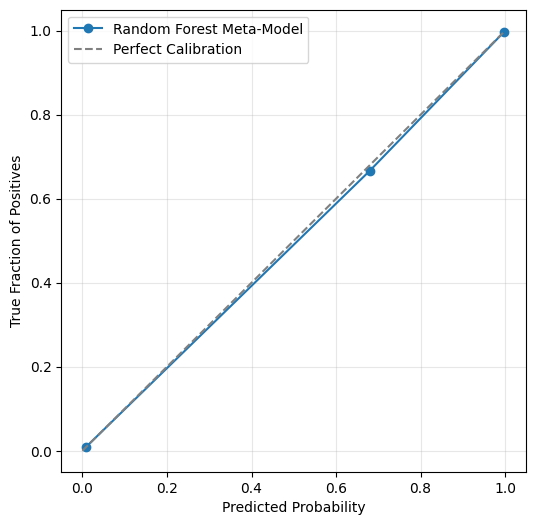

Brier Score: 0.0053
Expected Calibration Error (ECE): 0.0004


In [25]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss
import matplotlib.pyplot as plt
import numpy as np

# --- Step 1: Predict probabilities on the same meta-data ---
meta_probs = meta_model_rf.predict_proba(X_meta)[:, 1]
meta_preds = meta_model_rf.predict(X_meta)
y_meta_test = y_test[:1000]  # for clarity

# --- Step 2: Compute reliability curve (15 bins) ---
prob_true, prob_pred = calibration_curve(y_meta_test, meta_probs, n_bins=15, strategy='uniform')

# --- Step 3: Compute Brier score ---
brier = brier_score_loss(y_meta_test, meta_probs)

# --- Step 4: Compute Expected Calibration Error (ECE) ---
def compute_ece(y_true, y_prob, n_bins=15):
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    binids = np.digitize(y_prob, bins) - 1
    ece = 0.0
    for i in range(n_bins):
        bin_mask = binids == i
        if np.any(bin_mask):
            acc = np.mean(y_true[bin_mask])
            conf = np.mean(y_prob[bin_mask])
            ece += np.abs(acc - conf) * np.mean(bin_mask)
    return ece

ece = compute_ece(y_meta_test, meta_probs, n_bins=15)

# --- Step 5: Plot Reliability Curve ---
plt.figure(figsize=(6,6))
plt.plot(prob_pred, prob_true, marker='o', label='Random Forest Meta-Model')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Perfect Calibration')
# plt.title('Reliability Curve (Random Forest Meta-Model)')
plt.xlabel('Predicted Probability')
plt.ylabel('True Fraction of Positives')
plt.legend(loc='upper left')
plt.grid(alpha=0.3)
# plt.text(0.05, 0.9, f'Brier: {brier:.4f}\nECE: {ece:.4f}', transform=plt.gca().transAxes,
#          bbox=dict(facecolor='white', alpha=0.7))
plt.show()

print(f"Brier Score: {brier:.4f}")
print(f"Expected Calibration Error (ECE): {ece:.4f}")


In [ ]:
plt.savefig('reliability_curve.png', format='png', dpi=300, bbox_inches='tight', pad_inches=0.05)

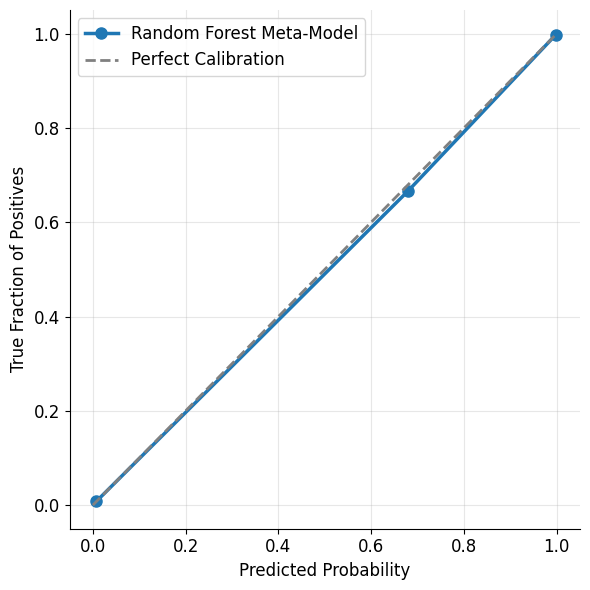

Brier Score: 0.0053
Expected Calibration Error (ECE): 0.0004


In [26]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss
import matplotlib.pyplot as plt
import numpy as np

# --- Step 1: Predict probabilities on the same meta-data ---
meta_probs = meta_model_rf.predict_proba(X_meta)[:, 1]
meta_preds = meta_model_rf.predict(X_meta)
y_meta_test = y_test[:1000]  # for clarity

# --- Step 2: Compute reliability curve (15 bins) ---
prob_true, prob_pred = calibration_curve(y_meta_test, meta_probs, n_bins=15, strategy='uniform')

# --- Step 3: Compute Brier score ---
brier = brier_score_loss(y_meta_test, meta_probs)

# --- Step 4: Compute Expected Calibration Error (ECE) ---
def compute_ece(y_true, y_prob, n_bins=15):
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    binids = np.digitize(y_prob, bins) - 1
    ece = 0.0
    for i in range(n_bins):
        bin_mask = binids == i
        if np.any(bin_mask):
            acc = np.mean(y_true[bin_mask])
            conf = np.mean(y_prob[bin_mask])
            ece += np.abs(acc - conf) * np.mean(bin_mask)
    return ece

ece = compute_ece(y_meta_test, meta_probs, n_bins=15)

# --- Step 5: Plot Reliability Curve (cleaned up for paper) ---
plt.figure(figsize=(6, 6))

# Plot the reliability curve
plt.plot(prob_pred, prob_true, marker='o', linewidth=2.5, markersize=8, 
         color='#1f77b4', label='Random Forest Meta-Model')

# Plot perfect calibration line
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', linewidth=2, 
         label='Perfect Calibration')

# Labels with font size 12
plt.xlabel('Predicted Probability', fontsize=12)
plt.ylabel('True Fraction of Positives', fontsize=12)

# Legend with font size 12
plt.legend(loc='upper left', fontsize=12, frameon=True)

# Grid
plt.grid(alpha=0.3)

# Tick labels font size 12
plt.tick_params(axis='both', labelsize=12)

# Remove top and right spines for cleaner look
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Tight layout
plt.tight_layout()

# Save
plt.savefig('reliability_curve.pdf', format='pdf', dpi=300, bbox_inches='tight', pad_inches=0.05)
plt.savefig('reliability_curve.png', format='png', dpi=300, bbox_inches='tight', pad_inches=0.05)

plt.show()

# Print metrics separately (not on plot)
print(f"Brier Score: {brier:.4f}")
print(f"Expected Calibration Error (ECE): {ece:.4f}")

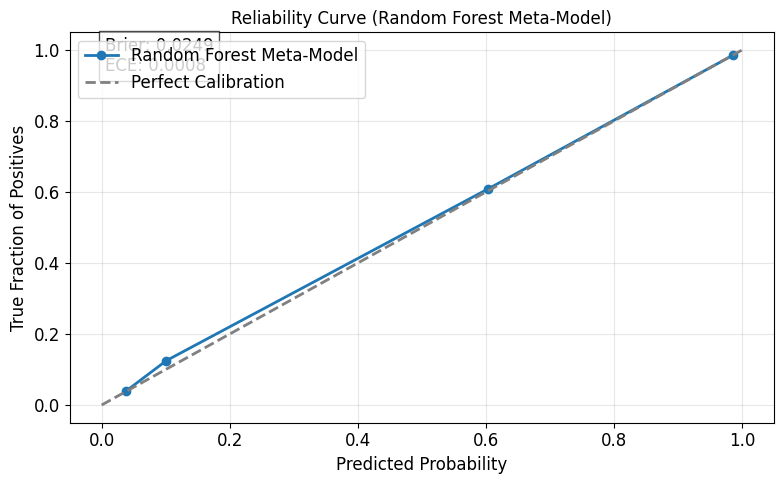

Brier Score: 0.0249
Expected Calibration Error (ECE): 0.0008


In [ ]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss
import matplotlib.pyplot as plt
import numpy as np

# --- Step 1: Predict probabilities on the same meta-data ---
meta_probs = meta_model_rf.predict_proba(X_meta)[:, 1]
meta_preds = meta_model_rf.predict(X_meta)
y_meta_test = y_test[:1000]  # for clarity

# --- Step 2: Compute reliability curve (15 bins) ---
prob_true, prob_pred = calibration_curve(y_meta_test, meta_probs, n_bins=15, strategy='uniform')

# --- Step 3: Compute Brier score ---
brier = brier_score_loss(y_meta_test, meta_probs)

# --- Step 4: Compute Expected Calibration Error (ECE) ---
def compute_ece(y_true, y_prob, n_bins=15):
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    binids = np.digitize(y_prob, bins) - 1
    ece = 0.0
    for i in range(n_bins):
        bin_mask = binids == i
        if np.any(bin_mask):
            acc = np.mean(y_true[bin_mask])
            conf = np.mean(y_prob[bin_mask])
            ece += np.abs(acc - conf) * np.mean(bin_mask)
    return ece

ece = compute_ece(y_meta_test, meta_probs, n_bins=15)

# --- Step 5: Plot Reliability Curve ---
plt.figure(figsize=(8, 5))  # Changed from (6,6) to (8,5) - wider and shorter
plt.plot(prob_pred, prob_true, marker='o', label='Random Forest Meta-Model', linewidth=2, markersize=6)
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Perfect Calibration', linewidth=2)
plt.title('Reliability Curve (Random Forest Meta-Model)', fontsize=12)
plt.xlabel('Predicted Probability', fontsize=12)
plt.ylabel('True Fraction of Positives', fontsize=12)
plt.legend(loc='upper left', fontsize=12)
plt.grid(alpha=0.3)
plt.tick_params(axis='both', which='major', labelsize=12)  # Set tick label fontsize
plt.text(0.05, 0.9, f'Brier: {brier:.4f}\nECE: {ece:.4f}', transform=plt.gca().transAxes,
         fontsize=12, bbox=dict(facecolor='white', alpha=0.7))
plt.tight_layout()
plt.show()

print(f"Brier Score: {brier:.4f}")
print(f"Expected Calibration Error (ECE): {ece:.4f}")

In [ ]:
import pennylane as qml
import numpy as np
import pandas as pd
from collections import Counter

def analyze_qnn_complexity(n_qubits, n_layers):
    """Analyze circuit structure (expanded) for QNN with StronglyEntanglingLayers."""
    
    dev = qml.device("default.qubit", wires=n_qubits)
    
    @qml.qnode(dev)
    def qnn_circuit(params):
        qml.templates.StronglyEntanglingLayers(params, wires=range(n_qubits))
        return qml.expval(qml.PauliZ(0))
    
    # Random parameters for given configuration
    shape = qml.StronglyEntanglingLayers.shape(n_layers=n_layers, n_wires=n_qubits)
    params = np.random.random(shape)
    
    # ---- Build & expand the circuit to count internal gates ----
    tape = qnn_circuit.construct((params,), {})
    expanded_tape = tape.expand(depth=5)  # force full decomposition into native gates
    
    # Extract true operations after expansion
    ops = expanded_tape.operations
    gate_count = len(ops)
    gate_types = Counter([op.name for op in ops])
    
    # ---- Compute circuit depth in a version-safe way ----
    try:
        # Newer PennyLane (≥0.34)
        depth = qml.resource.circuit_depth(qml.tape.QuantumScript(ops, expanded_tape.measurements))
    except Exception:
        try:
            # Older API location
            depth = qml.transforms.circuit_depth(qml.tape.QuantumScript(ops, expanded_tape.measurements))
        except Exception:
            # Fallback: approximate depth = number of layers * 2 (safe heuristic)
            depth = n_layers * 2
    
    return {
        "Qubits": n_qubits,
        "Layers": n_layers,
        "Gates": gate_count,
        "Depth": depth,
        "Gate_Types": dict(gate_types)
    }

# --- Scalability test ---
results = []
for n_qubits in [1,2,3,4,5,6,7,8,9,10,11,12,13]:
    for n_layers in [1, 2, 3, 4, 5, 6, 7]:
        stats = analyze_qnn_complexity(n_qubits, n_layers)
        results.append(stats)
        print(f"Qubits={n_qubits}, Layers={n_layers} → Depth={stats['Depth']}, Gates={stats['Gates']}")

scalability_df = pd.DataFrame(results)
display(scalability_df)


Qubits=1, Layers=1 → Depth=2, Gates=3
Qubits=1, Layers=2 → Depth=4, Gates=6
Qubits=1, Layers=3 → Depth=6, Gates=9
Qubits=1, Layers=4 → Depth=8, Gates=12
Qubits=1, Layers=5 → Depth=10, Gates=15
Qubits=1, Layers=6 → Depth=12, Gates=18
Qubits=1, Layers=7 → Depth=14, Gates=21
Qubits=2, Layers=1 → Depth=2, Gates=8
Qubits=2, Layers=2 → Depth=4, Gates=16
Qubits=2, Layers=3 → Depth=6, Gates=24
Qubits=2, Layers=4 → Depth=8, Gates=32
Qubits=2, Layers=5 → Depth=10, Gates=40
Qubits=2, Layers=6 → Depth=12, Gates=48
Qubits=2, Layers=7 → Depth=14, Gates=56
Qubits=3, Layers=1 → Depth=2, Gates=12
Qubits=3, Layers=2 → Depth=4, Gates=24
Qubits=3, Layers=3 → Depth=6, Gates=36
Qubits=3, Layers=4 → Depth=8, Gates=48
Qubits=3, Layers=5 → Depth=10, Gates=60
Qubits=3, Layers=6 → Depth=12, Gates=72
Qubits=3, Layers=7 → Depth=14, Gates=84
Qubits=4, Layers=1 → Depth=2, Gates=16
Qubits=4, Layers=2 → Depth=4, Gates=32
Qubits=4, Layers=3 → Depth=6, Gates=48
Qubits=4, Layers=4 → Depth=8, Gates=64
Qubits=4, Layers=5 →

,Qubits,Layers,Gates,Depth,Gate_Types
0,1,1,3,2,"{'RZ': 2, 'RY': 1}"
1,1,2,6,4,"{'RZ': 4, 'RY': 2}"
2,1,3,9,6,"{'RZ': 6, 'RY': 3}"
3,1,4,12,8,"{'RZ': 8, 'RY': 4}"
4,1,5,15,10,"{'RZ': 10, 'RY': 5}"
...,...,...,...,...,...
86,13,3,156,6,"{'RZ': 78, 'RY': 39, 'CNOT': 39}"
87,13,4,208,8,"{'RZ': 104, 'RY': 52, 'CNOT': 52}"
88,13,5,260,10,"{'RZ': 130, 'RY': 65, 'CNOT': 65}"
89,13,6,312,12,"{'RZ': 156, 'RY': 78, 'CNOT': 78}"


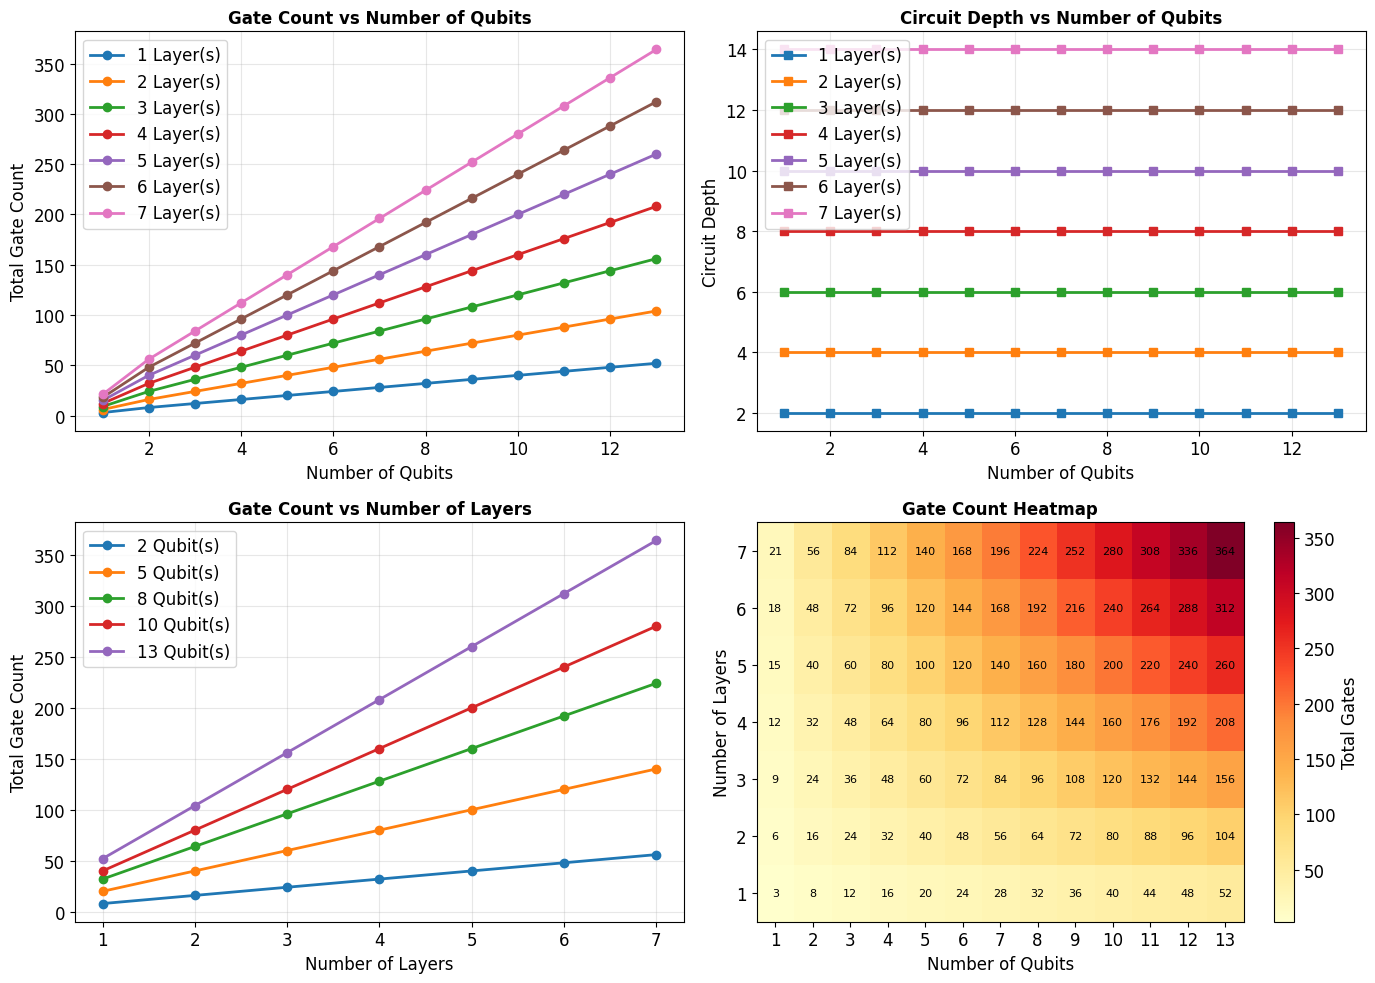

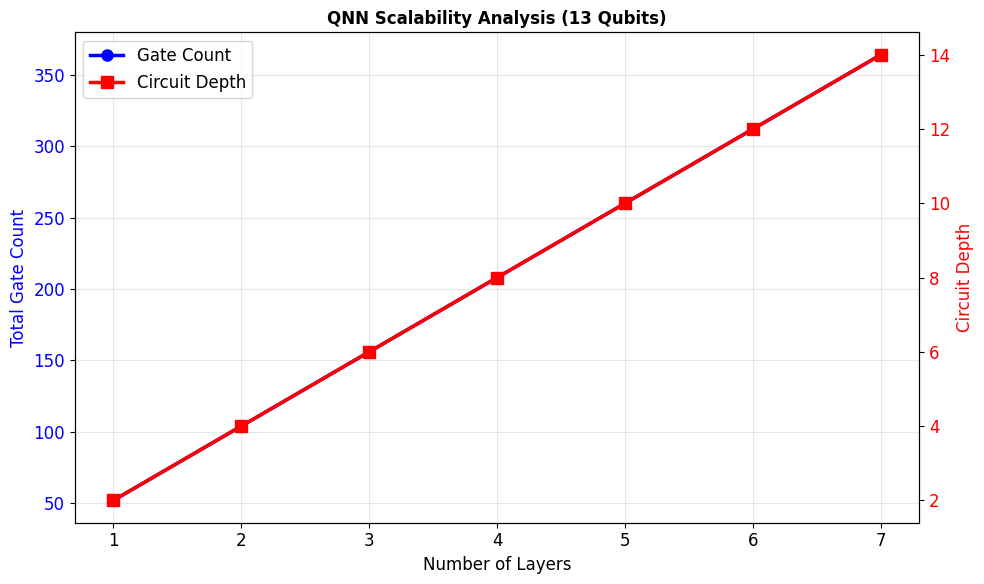


=== Scalability Analysis Summary ===

For 13 Qubits, 7 Layers (Your Configuration):
  Total Gates: 364
  Circuit Depth: 14
  Gate Types: {'RZ': 182, 'RY': 91, 'CNOT': 91}

Scaling Trends:
  Min Gates: 3 (at 1 qubits, 1 layers)
  Max Gates: 364 (at 13 qubits, 7 layers)
  Average Gates: 111.7


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Create visualizations for scalability analysis
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# --- Plot 1: Gate Count vs Qubits (for different layers) ---
ax1 = axes[0, 0]
for n_layers in [1, 2, 3, 4, 5, 6, 7]:
    data = scalability_df[scalability_df['Layers'] == n_layers]
    ax1.plot(data['Qubits'], data['Gates'], marker='o', label=f'{n_layers} Layer(s)', 
             linewidth=2, markersize=6)

ax1.set_xlabel('Number of Qubits', fontsize=12)
ax1.set_ylabel('Total Gate Count', fontsize=12)
ax1.set_title('Gate Count vs Number of Qubits', fontsize=12, weight='bold')
ax1.legend(fontsize=12, loc='upper left')
ax1.grid(True, alpha=0.3)
ax1.tick_params(axis='both', which='major', labelsize=12)

# --- Plot 2: Circuit Depth vs Qubits (for different layers) ---
ax2 = axes[0, 1]
for n_layers in [1, 2, 3, 4, 5, 6, 7]:
    data = scalability_df[scalability_df['Layers'] == n_layers]
    ax2.plot(data['Qubits'], data['Depth'], marker='s', label=f'{n_layers} Layer(s)', 
             linewidth=2, markersize=6)

ax2.set_xlabel('Number of Qubits', fontsize=12)
ax2.set_ylabel('Circuit Depth', fontsize=12)
ax2.set_title('Circuit Depth vs Number of Qubits', fontsize=12, weight='bold')
ax2.legend(fontsize=12, loc='upper left')
ax2.grid(True, alpha=0.3)
ax2.tick_params(axis='both', which='major', labelsize=12)

# --- Plot 3: Gate Count vs Layers (for different qubit counts) ---
ax3 = axes[1, 0]
qubit_samples = [2, 5, 8, 10, 13]  # Sample some qubit counts
for n_qubits in qubit_samples:
    data = scalability_df[scalability_df['Qubits'] == n_qubits]
    ax3.plot(data['Layers'], data['Gates'], marker='o', label=f'{n_qubits} Qubit(s)', 
             linewidth=2, markersize=6)

ax3.set_xlabel('Number of Layers', fontsize=12)
ax3.set_ylabel('Total Gate Count', fontsize=12)
ax3.set_title('Gate Count vs Number of Layers', fontsize=12, weight='bold')
ax3.legend(fontsize=12, loc='upper left')
ax3.grid(True, alpha=0.3)
ax3.tick_params(axis='both', which='major', labelsize=12)

# --- Plot 4: 3D Heatmap (Gates as function of both Qubits and Layers) ---
ax4 = axes[1, 1]
pivot_table = scalability_df.pivot(index='Layers', columns='Qubits', values='Gates')
im = ax4.imshow(pivot_table, aspect='auto', cmap='YlOrRd', origin='lower')

# Set ticks
ax4.set_xticks(range(len(pivot_table.columns)))
ax4.set_xticklabels(pivot_table.columns, fontsize=12)
ax4.set_yticks(range(len(pivot_table.index)))
ax4.set_yticklabels(pivot_table.index, fontsize=12)

ax4.set_xlabel('Number of Qubits', fontsize=12)
ax4.set_ylabel('Number of Layers', fontsize=12)
ax4.set_title('Gate Count Heatmap', fontsize=12, weight='bold')

# Add colorbar
cbar = plt.colorbar(im, ax=ax4)
cbar.set_label('Total Gates', fontsize=12)
cbar.ax.tick_params(labelsize=12)

# Add text annotations for gate counts
for i in range(len(pivot_table.index)):
    for j in range(len(pivot_table.columns)):
        text = ax4.text(j, i, int(pivot_table.iloc[i, j]),
                       ha="center", va="center", color="black", fontsize=8)

plt.tight_layout()
plt.show()

# --- Additional: Single plot for paper/presentation ---
fig2, ax = plt.subplots(figsize=(10, 6))

# Plot gate count scaling for your specific configuration (13 qubits)
data_13q = scalability_df[scalability_df['Qubits'] == 13]
ax.plot(data_13q['Layers'], data_13q['Gates'], marker='o', color='blue', 
        label='Gate Count', linewidth=2.5, markersize=8)

# Add circuit depth on secondary y-axis
ax2 = ax.twinx()
ax2.plot(data_13q['Layers'], data_13q['Depth'], marker='s', color='red', 
         label='Circuit Depth', linewidth=2.5, markersize=8)

ax.set_xlabel('Number of Layers', fontsize=12)
ax.set_ylabel('Total Gate Count', fontsize=12, color='blue')
ax2.set_ylabel('Circuit Depth', fontsize=12, color='red')
ax.set_title('QNN Scalability Analysis (13 Qubits)', fontsize=12, weight='bold')
ax.tick_params(axis='y', labelcolor='blue', labelsize=12)
ax2.tick_params(axis='y', labelcolor='red', labelsize=12)
ax.tick_params(axis='x', labelsize=12)
ax.grid(True, alpha=0.3)

# Combine legends
lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines1 + lines2, labels1 + labels2, loc='upper left', fontsize=12)

plt.tight_layout()
plt.show()

# --- Print summary statistics ---
print("\n=== Scalability Analysis Summary ===")
print(f"\nFor 13 Qubits, 7 Layers (Your Configuration):")
config_stats = scalability_df[(scalability_df['Qubits'] == 13) & (scalability_df['Layers'] == 7)].iloc[0]
print(f"  Total Gates: {config_stats['Gates']}")
print(f"  Circuit Depth: {config_stats['Depth']}")
print(f"  Gate Types: {config_stats['Gate_Types']}")

print(f"\nScaling Trends:")
print(f"  Min Gates: {scalability_df['Gates'].min()} (at {scalability_df.loc[scalability_df['Gates'].idxmin(), 'Qubits']} qubits, {scalability_df.loc[scalability_df['Gates'].idxmin(), 'Layers']} layers)")
print(f"  Max Gates: {scalability_df['Gates'].max()} (at {scalability_df.loc[scalability_df['Gates'].idxmax(), 'Qubits']} qubits, {scalability_df.loc[scalability_df['Gates'].idxmax(), 'Layers']} layers)")
print(f"  Average Gates: {scalability_df['Gates'].mean():.1f}")

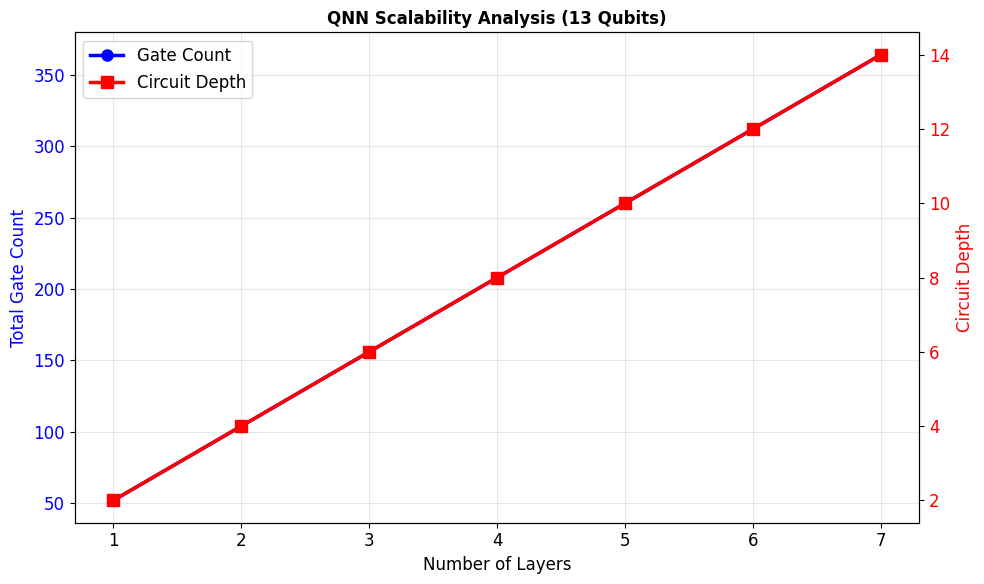

In [ ]:
# --- Best for Report: Single plot showing both metrics ---
fig, ax = plt.subplots(figsize=(10, 6))

# Plot gate count scaling for your specific configuration (13 qubits)
data_13q = scalability_df[scalability_df['Qubits'] == 13]
ax.plot(data_13q['Layers'], data_13q['Gates'], marker='o', color='blue', 
        label='Gate Count', linewidth=2.5, markersize=8)

# Add circuit depth on secondary y-axis
ax2 = ax.twinx()
ax2.plot(data_13q['Layers'], data_13q['Depth'], marker='s', color='red', 
         label='Circuit Depth', linewidth=2.5, markersize=8)

ax.set_xlabel('Number of Layers', fontsize=12)
ax.set_ylabel('Total Gate Count', fontsize=12, color='blue')
ax2.set_ylabel('Circuit Depth', fontsize=12, color='red')
ax.set_title('QNN Scalability Analysis (13 Qubits)', fontsize=12, weight='bold')
ax.tick_params(axis='y', labelcolor='blue', labelsize=12)
ax2.tick_params(axis='y', labelcolor='red', labelsize=12)
ax.tick_params(axis='x', labelsize=12)
ax.grid(True, alpha=0.3)

# Combine legends
lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines1 + lines2, labels1 + labels2, loc='upper left', fontsize=12)

plt.tight_layout()
plt.show()

/tmp/ipykernel_3235/2318122728.py:24: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


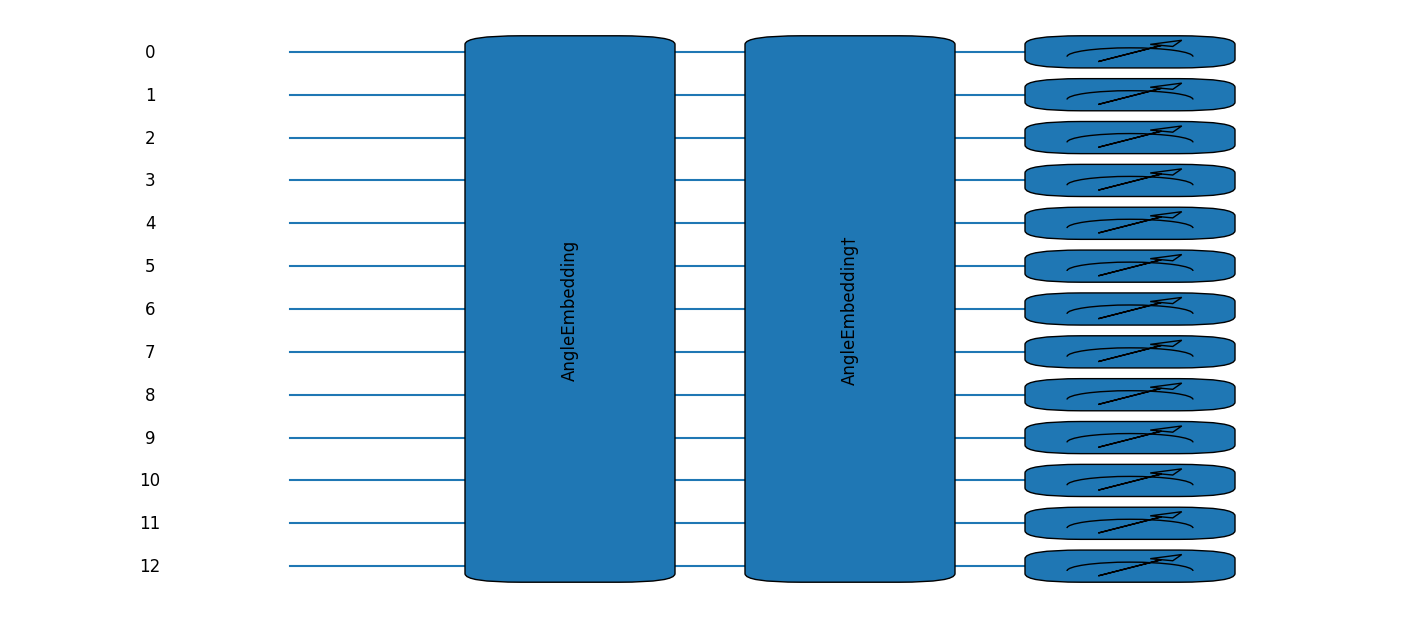

/tmp/ipykernel_3235/2318122728.py:74: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


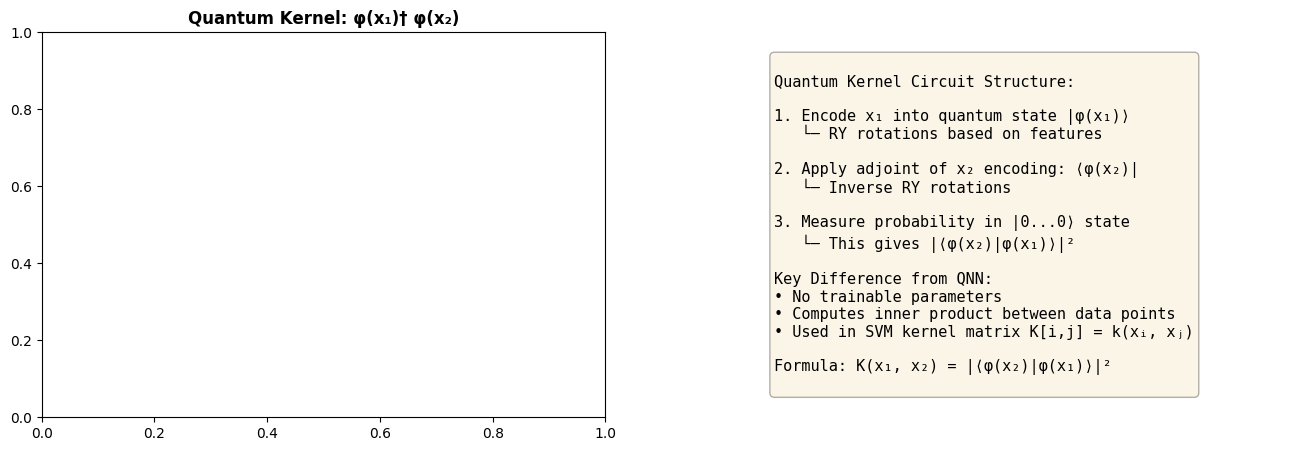

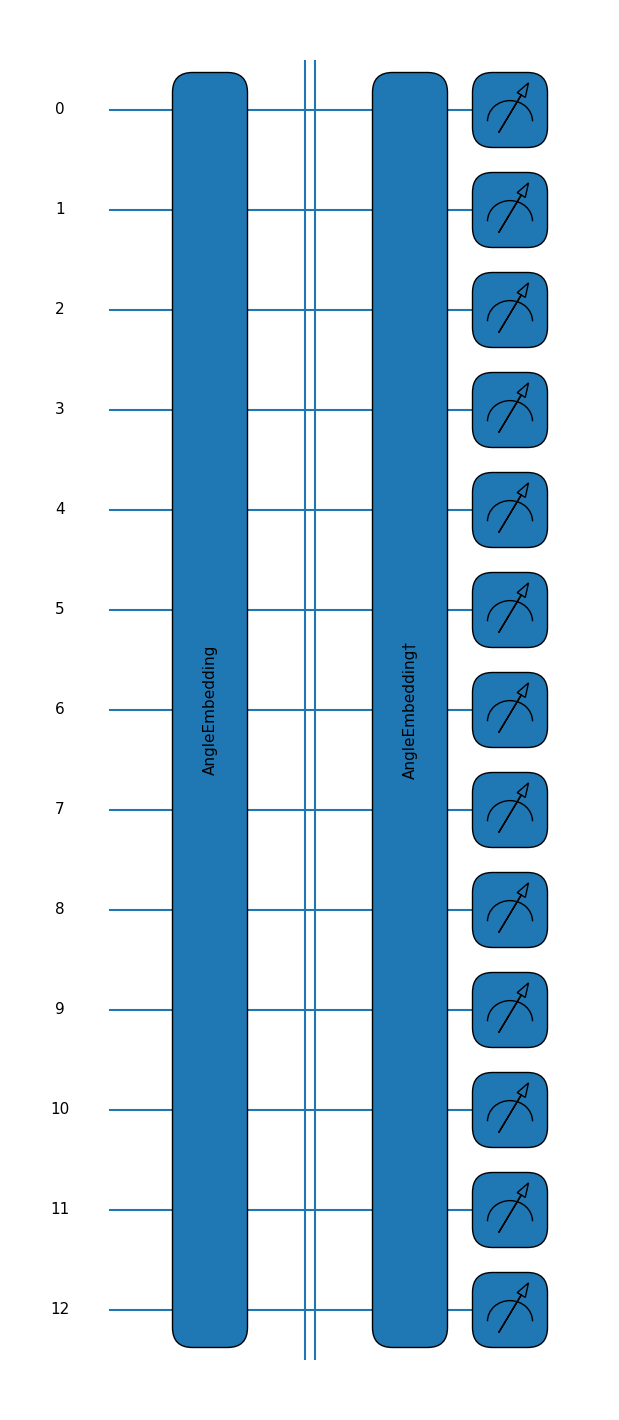

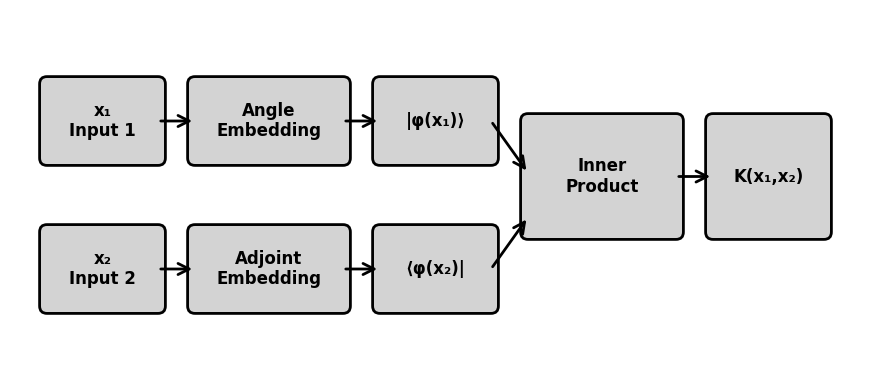


=== QSVM Kernel Circuit Information ===
Number of qubits: 13
Circuit type: Quantum Kernel (no trainable parameters)
Purpose: Compute inner product k(x₁, x₂) = |⟨φ(x₂)|φ(x₁)⟩|²

=== Text Representation ===
 0: ─╭AngleEmbedding(M0)─╭AngleEmbedding(M1)†─┤ ╭Probs
 1: ─├AngleEmbedding(M0)─├AngleEmbedding(M1)†─┤ ├Probs
 2: ─├AngleEmbedding(M0)─├AngleEmbedding(M1)†─┤ ├Probs
 3: ─├AngleEmbedding(M0)─├AngleEmbedding(M1)†─┤ ├Probs
 4: ─├AngleEmbedding(M0)─├AngleEmbedding(M1)†─┤ ├Probs
 5: ─├AngleEmbedding(M0)─├AngleEmbedding(M1)†─┤ ├Probs
 6: ─├AngleEmbedding(M0)─├AngleEmbedding(M1)†─┤ ├Probs
 7: ─├AngleEmbedding(M0)─├AngleEmbedding(M1)†─┤ ├Probs
 8: ─├AngleEmbedding(M0)─├AngleEmbedding(M1)†─┤ ├Probs
 9: ─├AngleEmbedding(M0)─├AngleEmbedding(M1)†─┤ ├Probs
10: ─├AngleEmbedding(M0)─├AngleEmbedding(M1)†─┤ ├Probs
11: ─├AngleEmbedding(M0)─├AngleEmbedding(M1)†─┤ ├Probs
12: ─╰AngleEmbedding(M0)─╰AngleEmbedding(M1)†─┤ ╰Probs

M0 = 
[0.53819314 0.65931452 0.02836669 0.38838759 0.27377471 0.96305596
 0.14

In [30]:
import pennylane as qml
import matplotlib.pyplot as plt
import numpy as np

# Assuming NUM_FEATURES is defined
NUM_FEATURES = 13  # Replace with your actual value

# Create device
dev_qsvm = qml.device("default.qubit", wires=NUM_FEATURES)

@qml.qnode(dev_qsvm)
def kernel_circuit(x1, x2):
    qml.AngleEmbedding(x1, wires=range(NUM_FEATURES))
    qml.adjoint(qml.AngleEmbedding)(x2, wires=range(NUM_FEATURES))
    return qml.probs(wires=range(NUM_FEATURES))

# Create dummy input data for visualization
x1_dummy = np.random.random(NUM_FEATURES)
x2_dummy = np.random.random(NUM_FEATURES)

# ===== Main Circuit Diagram =====
fig, ax = qml.draw_mpl(kernel_circuit, style='default', fontsize=12)(x1_dummy, x2_dummy)
fig.set_size_inches(14, 6)
plt.tight_layout()
plt.savefig('qsvm_kernel_circuit.pdf', format='pdf', dpi=300, bbox_inches='tight', pad_inches=0.1)
plt.savefig('qsvm_kernel_circuit.png', format='png', dpi=300, bbox_inches='tight', pad_inches=0.1)
plt.show()

# ===== Enhanced Comparison Figure =====
# Show what makes this different from QNN
fig2, axes = plt.subplots(1, 2, figsize=(16, 5))

# Left: Show the kernel structure with annotations
@qml.qnode(dev_qsvm)
def kernel_annotated(x1, x2):
    # Forward embedding
    qml.AngleEmbedding(x1, wires=range(NUM_FEATURES))
    qml.Barrier(wires=range(NUM_FEATURES))  # Visual separator
    # Adjoint (inverse) embedding
    qml.adjoint(qml.AngleEmbedding)(x2, wires=range(NUM_FEATURES))
    return qml.probs(wires=range(NUM_FEATURES))

ax1 = axes[0]
qml.draw_mpl(kernel_annotated, ax=ax1, style='default', fontsize=11)(x1_dummy, x2_dummy)
ax1.set_title('Quantum Kernel: φ(x₁)† φ(x₂)', fontsize=12, fontweight='bold')

# Right: Show computation explanation
ax2 = axes[1]
ax2.axis('off')
explanation = """
Quantum Kernel Circuit Structure:

1. Encode x₁ into quantum state |φ(x₁)⟩
   └─ RY rotations based on features

2. Apply adjoint of x₂ encoding: ⟨φ(x₂)|
   └─ Inverse RY rotations

3. Measure probability in |0...0⟩ state
   └─ This gives |⟨φ(x₂)|φ(x₁)⟩|²

Key Difference from QNN:
• No trainable parameters
• Computes inner product between data points
• Used in SVM kernel matrix K[i,j] = k(xᵢ, xⱼ)

Formula: K(x₁, x₂) = |⟨φ(x₂)|φ(x₁)⟩|²
"""

ax2.text(0.1, 0.5, explanation, fontsize=11, family='monospace',
         verticalalignment='center', bbox=dict(boxstyle='round', 
         facecolor='wheat', alpha=0.3))

plt.tight_layout()
plt.savefig('qsvm_kernel_explained.pdf', format='pdf', dpi=300, bbox_inches='tight')
plt.savefig('qsvm_kernel_explained.png', format='png', dpi=300, bbox_inches='tight')
plt.show()

# ===== Simplified Schematic =====
fig3, ax3 = plt.subplots(figsize=(10, 4))
ax3.axis('off')

# Create a simplified block diagram
from matplotlib.patches import Rectangle, FancyBboxPatch, FancyArrowPatch

boxes = [
    {'xy': (0.5, 3), 'width': 1.5, 'height': 1, 'label': 'x₁\nInput 1', 'color': 'lightgray'},
    {'xy': (2.5, 3), 'width': 2, 'height': 1, 'label': 'Angle\nEmbedding', 'color': 'lightgray'},
    {'xy': (5, 3), 'width': 1.5, 'height': 1, 'label': '|φ(x₁)⟩', 'color': 'lightgray'},
    {'xy': (0.5, 1), 'width': 1.5, 'height': 1, 'label': 'x₂\nInput 2', 'color': 'lightgray'},
    {'xy': (2.5, 1), 'width': 2, 'height': 1, 'label': 'Adjoint\nEmbedding', 'color': 'lightgray'},
    {'xy': (5, 1), 'width': 1.5, 'height': 1, 'label': '⟨φ(x₂)|', 'color': 'lightgray'},
    {'xy': (7, 2), 'width': 2, 'height': 1.5, 'label': 'Inner\nProduct', 'color': 'lightgray'},
    {'xy': (9.5, 2), 'width': 1.5, 'height': 1.5, 'label': 'K(x₁,x₂)', 'color': 'lightgray'},
]

for box in boxes:
    fancy_box = FancyBboxPatch((box['xy'][0], box['xy'][1]), box['width'], box['height'],
                               boxstyle="round,pad=0.1", edgecolor='black', 
                               facecolor=box['color'], linewidth=2)
    ax3.add_patch(fancy_box)
    ax3.text(box['xy'][0] + box['width']/2, box['xy'][1] + box['height']/2, 
             box['label'], ha='center', va='center', fontsize=12, fontweight='bold')

# Add arrows
arrows = [
    ((2, 3.5), (2.5, 3.5)),
    ((4.5, 3.5), (5, 3.5)),
    ((2, 1.5), (2.5, 1.5)),
    ((4.5, 1.5), (5, 1.5)),
    ((6.5, 3.5), (7, 2.8)),
    ((6.5, 1.5), (7, 2.2)),
    ((9, 2.75), (9.5, 2.75)),
]

for start, end in arrows:
    arrow = FancyArrowPatch(start, end, arrowstyle='->', 
                           mutation_scale=20, linewidth=2, color='black')
    ax3.add_patch(arrow)

ax3.set_xlim(0, 11.5)
ax3.set_ylim(0, 5)
ax3.set_aspect('equal')

plt.tight_layout()
plt.savefig('qsvm_kernel_schematic.pdf', format='pdf', dpi=300, bbox_inches='tight')
plt.savefig('qsvm_kernel_schematic.png', format='png', dpi=300, bbox_inches='tight')
plt.show()

# ===== Print Information =====
print("\n=== QSVM Kernel Circuit Information ===")
print(f"Number of qubits: {NUM_FEATURES}")
print(f"Circuit type: Quantum Kernel (no trainable parameters)")
print(f"Purpose: Compute inner product k(x₁, x₂) = |⟨φ(x₂)|φ(x₁)⟩|²")
print("\n=== Text Representation ===")
print(qml.draw(kernel_circuit, decimals=2)(x1_dummy, x2_dummy))

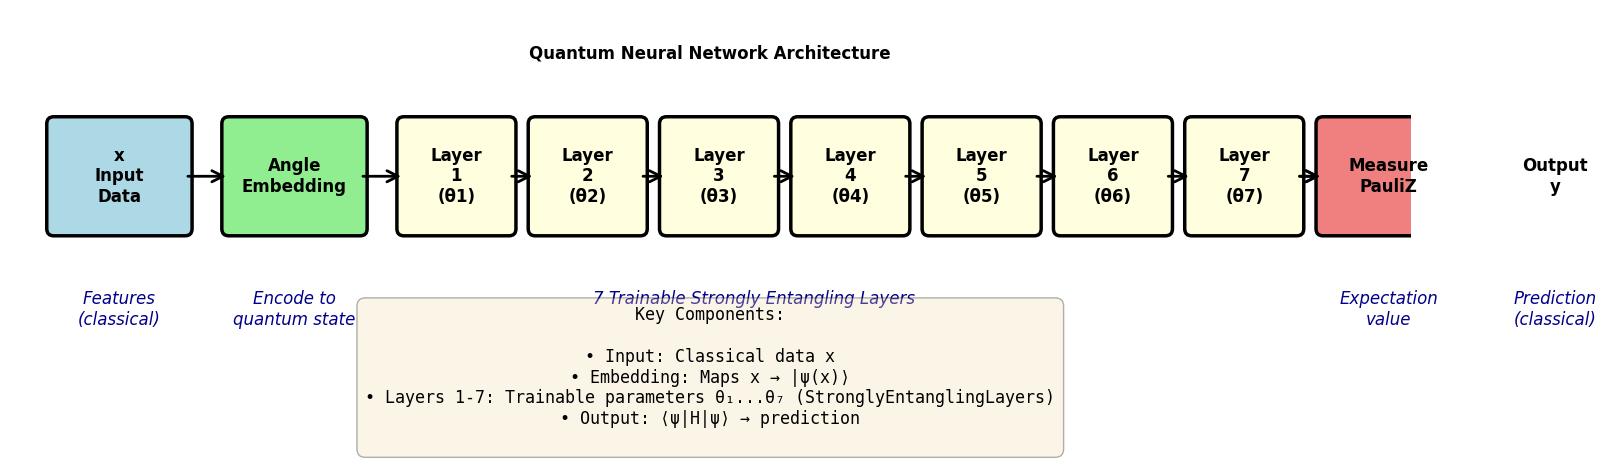

QNN circuit schematic with 7 separate layers saved!


In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
import numpy as np

# Create figure with more width for 7 layers
fig, ax = plt.subplots(figsize=(16, 5))
ax.axis('off')

# Define boxes for QNN architecture with 7 separate layers
boxes = [
    {'xy': (0.5, 2), 'width': 1.5, 'height': 1.2, 'label': 'x\nInput\nData', 'color': 'lightblue'},
    {'xy': (2.5, 2), 'width': 1.5, 'height': 1.2, 'label': 'Angle\nEmbedding', 'color': 'lightgreen'},
]

# Add 7 strongly entangling layers
layer_start_x = 4.5
layer_width = 1.2
layer_spacing = 0.3

for i in range(7):
    x_pos = layer_start_x + i * (layer_width + layer_spacing)
    boxes.append({
        'xy': (x_pos, 2), 
        'width': layer_width, 
        'height': 1.2, 
        'label': f'Layer\n{i+1}\n(θ{i+1})', 
        'color': 'lightyellow'
    })

# Add measurement and output
boxes.append({'xy': (layer_start_x + 7 * (layer_width + layer_spacing), 2), 'width': 1.5, 'height': 1.2, 'label': 'Measure\nPauliZ', 'color': 'lightcoral'})
boxes.append({'xy': (layer_start_x + 7 * (layer_width + layer_spacing) + 2, 2), 'width': 1.3, 'height': 1.2, 'label': 'Output\ny', 'color': 'plum'})

# Draw boxes
for box in boxes:
    fancy_box = FancyBboxPatch(
        (box['xy'][0], box['xy'][1]), 
        box['width'], 
        box['height'],
        boxstyle="round,pad=0.08", 
        edgecolor='black', 
        facecolor=box['color'], 
        linewidth=2.5
    )
    ax.add_patch(fancy_box)
    ax.text(
        box['xy'][0] + box['width']/2, 
        box['xy'][1] + box['height']/2, 
        box['label'], 
        ha='center', 
        va='center', 
        fontsize=12, 
        fontweight='bold'
    )

# Add arrows between all boxes
arrow_positions = []
# First arrow
arrow_positions.append(((2, 2.6), (2.5, 2.6)))
# Second arrow
arrow_positions.append(((4, 2.6), (4.5, 2.6)))

# Arrows between layers
for i in range(7):
    start_x = layer_start_x + i * (layer_width + layer_spacing) + layer_width
    end_x = layer_start_x + (i + 1) * (layer_width + layer_spacing)
    arrow_positions.append(((start_x, 2.6), (end_x, 2.6)))

# Arrow to measurement
last_layer_end = layer_start_x + 6 * (layer_width + layer_spacing) + layer_width
measure_start = layer_start_x + 7 * (layer_width + layer_spacing)
arrow_positions.append(((last_layer_end, 2.6), (measure_start, 2.6)))

# Arrow to output
output_start = layer_start_x + 7 * (layer_width + layer_spacing) + 1.5
output_arrow = layer_start_x + 7 * (layer_width + layer_spacing) + 2
arrow_positions.append(((output_start, 2.6), (output_arrow, 2.6)))

for start, end in arrow_positions:
    arrow = FancyArrowPatch(
        start, end, 
        arrowstyle='->', 
        mutation_scale=20, 
        linewidth=2, 
        color='black'
    )
    ax.add_patch(arrow)

# Add annotations below boxes
annotations = [
    {'xy': (1.25, 1.3), 'text': 'Features\n(classical)', 'fontsize': 12},
    {'xy': (3.25, 1.3), 'text': 'Encode to\nquantum state', 'fontsize': 12},
    {'xy': (8.5, 1.3), 'text': '7 Trainable Strongly Entangling Layers', 'fontsize': 12},
    {'xy': (measure_start + 0.75, 1.3), 'text': 'Expectation\nvalue', 'fontsize': 12},
    {'xy': (output_arrow + 0.65, 1.3), 'text': 'Prediction\n(classical)', 'fontsize': 12},
]

for annot in annotations:
    ax.text(
        annot['xy'][0], 
        annot['xy'][1], 
        annot['text'], 
        ha='center', 
        va='top', 
        fontsize=annot['fontsize'], 
        style='italic',
        color='darkblue'
    )

# Add title above
ax.text(
    8, 4, 
    'Quantum Neural Network Architecture', 
    ha='center', 
    va='center', 
    fontsize=12, 
    fontweight='bold'
)

# Add circuit details at the bottom
details_text = """Key Components:

• Input: Classical data x
• Embedding: Maps x → |ψ(x)⟩
• Layers 1-7: Trainable parameters θ₁...θ₇ (StronglyEntanglingLayers)
• Output: ⟨ψ|H|ψ⟩ → prediction
"""

ax.text(
    8, 0.3, 
    details_text, 
    ha='center', 
    va='center', 
    fontsize=12, 
    family='monospace',
    bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.3, pad=0.5)
)

# Set axis limits
ax.set_xlim(0, 16)
ax.set_ylim(0, 4.5)
ax.set_aspect('equal')

plt.tight_layout()

# Save figure
plt.savefig('qnn_circuit_schematic.pdf', format='pdf', dpi=300, bbox_inches='tight', pad_inches=0.1)
plt.savefig('qnn_circuit_schematic.png', format='png', dpi=300, bbox_inches='tight', pad_inches=0.1)

plt.show()d

print("QNN circuit schematic with 7 separate layers saved!")

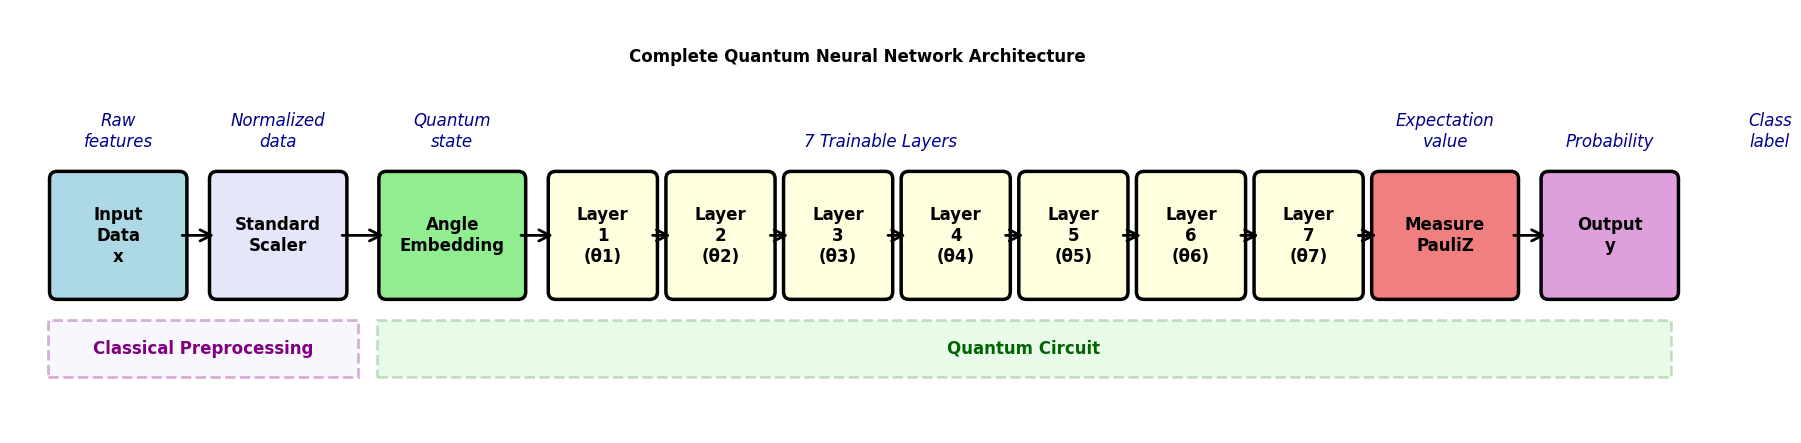

In [35]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Rectangle
import numpy as np

# Create figure
fig, ax = plt.subplots(figsize=(18, 6))
ax.axis('off')

# Define boxes for complete architecture
boxes = []

# Classical preprocessing
boxes.append({'xy': (0.5, 2.5), 'width': 1.3, 'height': 1.2, 'label': 'Input\nData\nx', 'color': 'lightblue'})
boxes.append({'xy': (2.2, 2.5), 'width': 1.3, 'height': 1.2, 'label': 'Standard\nScaler', 'color': 'lavender'})

# Quantum part
boxes.append({'xy': (4.0, 2.5), 'width': 1.4, 'height': 1.2, 'label': 'Angle\nEmbedding', 'color': 'lightgreen'})

# Add 7 strongly entangling layers
layer_start_x = 5.8
layer_width = 1.0
layer_spacing = 0.25

for i in range(7):
    x_pos = layer_start_x + i * (layer_width + layer_spacing)
    boxes.append({
        'xy': (x_pos, 2.5), 
        'width': layer_width, 
        'height': 1.2, 
        'label': f'Layer\n{i+1}\n(θ{i+1})', 
        'color': 'lightyellow'
    })

# Measurement
measure_x = layer_start_x + 7 * (layer_width + layer_spacing)
boxes.append({'xy': (measure_x, 2.5), 'width': 1.4, 'height': 1.2, 'label': 'Measure\nPauliZ', 'color': 'lightcoral'})

# Output
output_x = measure_x + 1.8
boxes.append({'xy': (output_x, 2.5), 'width': 1.3, 'height': 1.2, 'label': 'Output\ny', 'color': 'plum'})

# Draw boxes
for box in boxes:
    fancy_box = FancyBboxPatch(
        (box['xy'][0], box['xy'][1]), 
        box['width'], 
        box['height'],
        boxstyle="round,pad=0.08", 
        edgecolor='black', 
        facecolor=box['color'], 
        linewidth=2.5
    )
    ax.add_patch(fancy_box)
    ax.text(
        box['xy'][0] + box['width']/2, 
        box['xy'][1] + box['height']/2, 
        box['label'], 
        ha='center', 
        va='center', 
        fontsize=12, 
        fontweight='bold'
    )

# Add arrows between all boxes
arrow_positions = []

# Arrows in classical preprocessing
arrow_positions.append(((1.8, 3.1), (2.2, 3.1)))
arrow_positions.append(((3.5, 3.1), (4.0, 3.1)))

# Arrow to first quantum layer
arrow_positions.append(((5.4, 3.1), (5.8, 3.1)))

# Arrows between quantum layers
for i in range(7):
    start_x = layer_start_x + i * (layer_width + layer_spacing) + layer_width
    end_x = layer_start_x + (i + 1) * (layer_width + layer_spacing)
    arrow_positions.append(((start_x, 3.1), (end_x, 3.1)))

# Arrow to measurement
last_layer_end = layer_start_x + 6 * (layer_width + layer_spacing) + layer_width
arrow_positions.append(((last_layer_end, 3.1), (measure_x, 3.1)))

# Arrow to output
arrow_positions.append(((measure_x + 1.4, 3.1), (output_x, 3.1)))

for start, end in arrow_positions:
    arrow = FancyArrowPatch(
        start, end, 
        arrowstyle='->', 
        mutation_scale=20, 
        linewidth=2, 
        color='black'
    )
    ax.add_patch(arrow)

# Add section labels with background rectangles (BELOW the boxes)
# Classical preprocessing section
classical_pre_rect = Rectangle(
    (0.4, 1.6), 3.3, 0.6,
    edgecolor='purple', 
    facecolor='lavender', 
    linewidth=2,
    linestyle='--',
    alpha=0.3
)
ax.add_patch(classical_pre_rect)
ax.text(2.05, 1.9, 'Classical Preprocessing', ha='center', va='center', 
        fontsize=12, fontweight='bold', color='purple')

# Quantum section
quantum_rect = Rectangle(
    (3.9, 1.6), output_x + 1.3 - 3.9, 0.6,
    edgecolor='darkgreen', 
    facecolor='lightgreen', 
    linewidth=2,
    linestyle='--',
    alpha=0.2
)
ax.add_patch(quantum_rect)
ax.text((3.9 + output_x + 1.3)/2, 1.9, 'Quantum Circuit', ha='center', va='center', 
        fontsize=12, fontweight='bold', color='darkgreen')

# Remove classical post-processing section (no longer needed)

# Add annotations ABOVE boxes
annotations = [
    {'xy': (1.15, 4.0), 'text': 'Raw\nfeatures', 'fontsize': 12},
    {'xy': (2.85, 4.0), 'text': 'Normalized\ndata', 'fontsize': 12},
    {'xy': (4.7, 4.0), 'text': 'Quantum\nstate', 'fontsize': 12},
    {'xy': (9.25, 4.0), 'text': '7 Trainable Layers', 'fontsize': 12},
    {'xy': (measure_x + 0.7, 4.0), 'text': 'Expectation\nvalue', 'fontsize': 12},
    {'xy': (postprocess_x + 0.65, 4.0), 'text': 'Probability', 'fontsize': 12},
    {'xy': (postprocess_x + 2.35, 4.0), 'text': 'Class\nlabel', 'fontsize': 12},
]

for annot in annotations:
    ax.text(
        annot['xy'][0], 
        annot['xy'][1], 
        annot['text'], 
        ha='center', 
        va='bottom', 
        fontsize=annot['fontsize'], 
        style='italic',
        color='darkblue'
    )

# Add title at top
ax.text(
    9, 5.0, 
    'Complete Quantum Neural Network Architecture', 
    ha='center', 
    va='center', 
    fontsize=12, 
    fontweight='bold'
)

# Set axis limits
ax.set_xlim(0, 18)
ax.set_ylim(1.0, 5.5)
ax.set_aspect('equal')

plt.tight_layout()

# Save figure
# plt.savefig('qnn_complete_architecture.pdf', format='pdf', dpi=300, bbox_inches='tight', pad_inches=0.1)
# plt.savefig('qnn_complete_architecture.png', format='png', dpi=300, bbox_inches='tight', pad_inches=0.1)

plt.show()

# print("Complete QNN architecture with classical layers saved!")